# Persiapan Model

In [1]:
!git clone https://github.com/maugi1547/thesis-Difficulty-Aware-Router

Cloning into 'thesis-Difficulty-Aware-Router'...
remote: Enumerating objects: 51464, done.
remote: Counting objects: 100% (373/373), done.
remote: Compressing objects: 100% (301/301), done.
remote: Total 51464 (delta 174), reused 135 (delta 72), pack-reused 51091 (from 2)
Receiving objects: 100% (51464/51464), 29.28 MiB | 21.60 MiB/s, done.
Resolving deltas: 100% (34734/34734), done.


In [1]:
# Change the current working directory to the ultralytics folder
# This ensures that 'pip install -e .' looks for setup.py/pyproject.toml in the correct place
%cd /kaggle/working/thesis-Difficulty-Aware-Router
# Install ultralytics in editable mode
# -e .  means 'install in editable mode from the current directory'
!pip install -e .
import ultralytics
print(ultralytics.__file__)

/kaggle/working/thesis-Difficulty-Aware-Router
Obtaining file:///kaggle/working/thesis-Difficulty-Aware-Router
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ultralytics (pyproject.toml) ... done
  Created wheel for ultralytics: filename=ultralytics-8.3.240-0.editable-py3-none-any.whl size=23203 sha256=c8a15cbbf2a47a5b049e6a30207bf2bcf358dec2a8ed94c0afa6b4cc534adc69
  Stored in directory: /tmp/pip-ephem-wheel-cache-nr6t_oj2/wheels/3e/26/f6/a64eb84ee291363980b7b22df9872c97cd232c4a36cfe247e3
Successfully built ultralytics
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#

In [2]:
import ultralytics
import os
import csv
import torch
from ultralytics.models.yolo.detect import DetectionValidator
from ultralytics.utils import LOGGER
from ultralytics import settings
from ultralytics.models.yolo.detect import DetectionTrainer
from copy import copy
from ultralytics.model_yolov8_router import DualBranchDetectionModel, DualBranchDetectionLoss

# ==============================================================================
# 1. PATCH LOSS.PY (LAMBDA DEFAULT + GUARD ANTI DOUBLE-COUNT ROUTER PENALTY)
# ==============================================================================
loss_path = os.path.join(os.path.dirname(ultralytics.__file__), 'utils', 'loss.py')

with open(loss_path, 'r') as f:
    content = f.read()

original_content = content

content = content.replace(
    "getattr(self.model, 'router_penalty_lambda', 0.05)",
    "getattr(self.model, 'router_penalty_lambda', 0.01)"
)
content = content.replace("target_lambda = 0.05", "target_lambda = 0.01")

guard_marker = "if not self.model.training:\n            return loss"
guard_injection = (
    "if not self.model.training:\n            return loss\n\n"
    "        # --- GUARD: cegah double-count router penalty dari loss_B (DualBranch) ---\n"
    "        if not getattr(self, '_compute_router_penalty', True):\n"
    "            if loss.shape[0] == 3:\n"
    "                loss = torch.cat([loss, torch.zeros(1, device=loss.device, dtype=loss.dtype)])\n"
    "            return loss\n"
)

if "_compute_router_penalty" in content:
    print("ℹ️  Guard _compute_router_penalty sudah ada, skip injection.")
elif guard_marker in content:
    content = content.replace(guard_marker, guard_injection)
    print("✅ Guard _compute_router_penalty berhasil di-inject ke loss.py")
else:
    print("⚠️  WARNING: guard_marker tidak ditemukan! compute_router_loss() TIDAK ter-patch. "
          "Cek manual isi loss.py sebelum lanjut training — loss_B kemungkinan akan "
          "dobel-hitung router penalty.")

if content != original_content:
    with open(loss_path, 'w') as f:
        f.write(content)
    print("✅ loss.py berhasil diperbarui.")
else:
    print("ℹ️  loss.py tidak berubah (kemungkinan sudah pernah dipatch sebelumnya).")


# ==============================================================================
# 2. TRAINER CUSTOM — MENGGANTIKAN YOLO() WRAPPER
# ==============================================================================
class DualBranchTrainer(DetectionTrainer):
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = DualBranchDetectionModel(cfg=cfg or self.args.model, ch=3, nc=self.data["nc"], verbose=verbose)
        if weights:
            model.load(weights)
        return model

    def set_model_attributes(self):
        super().set_model_attributes()
        # tidak perlu set loss_names di sini lagi

    def get_validator(self):
        self.loss_names = ("box_A", "cls_A", "dfl_A", "router", "proxy", "box_B", "cls_B", "dfl_B")
        return DetectionValidator(
            self.test_loader, save_dir=self.save_dir, args=copy(self.args), _callbacks=self.callbacks
        )

class DualBranchValidatorB(DetectionValidator):
    """
    DetectionValidator yang memaksa model mengevaluasi Branch B (No-P2)
    alih-alih default Branch A. Caranya: monkey-patch sementara
    `model._predict_once` supaya return det_B, bukan det_A, HANYA
    selama proses __call__ ini berlangsung — lalu dikembalikan ke semula.
    """

    def __call__(self, trainer=None, model=None):
        # --- Tentukan model target: prioritas argumen langsung, lalu trainer.ema, lalu trainer.model ---
        if model is not None:
            target_model = model
        elif trainer is not None:
            target_model = trainer.ema.ema if (hasattr(trainer, "ema") and trainer.ema) else trainer.model
        else:
            raise ValueError("DualBranchValidatorB butuh salah satu dari `trainer` atau `model`.")

        assert hasattr(target_model, "_predict_once_dual"), (
            "Model bukan DualBranchDetectionModel — tidak punya _predict_once_dual(). "
            "DualBranchValidatorB hanya valid untuk model dual-branch."
        )

        # --- Simpan method asli, ganti sementara ---
        original_predict_once = target_model._predict_once

        def branch_b_predict_once(x, profile=False, visualize=False, embed=None):
            _, det_B = target_model._predict_once_dual(x, profile, visualize, embed)
            return det_B

        target_model._predict_once = branch_b_predict_once

        try:
            result = super().__call__(trainer=trainer, model=model)
        finally:
            # --- WAJIB dikembalikan, apa pun hasilnya (termasuk kalau error) ---
            target_model._predict_once = original_predict_once

        return result
        
# ==============================================================================
# 3. CALLBACK: IDEAL CURRICULUM SCHEDULER (50-20-30 PHASE)
# ==============================================================================
# Di scheduler Anda (ideal_curriculum_scheduler), tambahkan:
def ideal_curriculum_scheduler(trainer):
    epoch = trainer.epoch + 1
    final_lambda = 0.3
    final_gate_value_weight = 0.5  # target akhir

    if epoch <= 50:
        new_lambda = 0.0
        # --- TAMBAHAN: ramp gate_value_weight terpisah, mulai naik dari epoch 10 (bukan 4) ---
        if epoch <= 10:
            new_gate_value_weight = 0.0
        else:
            progress = min((epoch - 10) / 20.0, 1.0)  # naik bertahap dari epoch 10 ke 30
            new_gate_value_weight = final_gate_value_weight * progress
        fase = "Fase 1: Eksplorasi Bebas (Fokus mAP)"
    elif epoch <= 80:
        progress = (epoch - 50) / 30.0
        new_lambda = final_lambda * progress
        new_gate_value_weight = final_gate_value_weight
        fase = "Fase 2: Transisi Efisiensi"
    else:
        new_lambda = final_lambda
        new_gate_value_weight = final_gate_value_weight
        fase = "Fase 3: Pemantapan Hard Routing"

    if hasattr(trainer, 'model'):
        trainer.model.router_penalty_lambda = new_lambda
        trainer.model.gate_value_loss_weight = new_gate_value_weight  # <-- TAMBAHAN

        if hasattr(trainer, 'train_loader'):
            trainer.model.total_batches = len(trainer.train_loader)

        for m in trainer.model.modules():
            if 'DifficultyAwareRouter' in m.__class__.__name__:
                m._is_warmup = False if epoch > 10 else getattr(m, '_is_warmup', True)  # <-- selaraskan ke 10, bukan 3
                break

    if hasattr(trainer, 'ema') and trainer.ema:
        trainer.ema.ema.router_penalty_lambda = new_lambda
        trainer.ema.ema.gate_value_loss_weight = new_gate_value_weight
        for m in trainer.ema.ema.modules():
            if 'DifficultyAwareRouter' in m.__class__.__name__:
                m._is_warmup = False if epoch > 10 else getattr(m, '_is_warmup', True)
                break

    if epoch % 5 == 0 or epoch in [1, 51, 81]:
        LOGGER.info(f"\n📈 [SCHEDULER] Epoch {epoch} | {fase} | Lambda: {new_lambda:.5f} | "
                    f"GateValueW: {new_gate_value_weight:.4f}")


# ==============================================================================
# 4. CALLBACK: MONITORING AKTIVASI P2
# ==============================================================================
def make_router_stat_checker(trainer_ref):
    val_router_stats = {"total_p2_prob": 0.0, "batch_count": 0}

    def on_val_start(validator):
        val_router_stats["total_p2_prob"] = 0.0
        val_router_stats["batch_count"] = 0

    def on_val_batch_end(validator):
        current_model = trainer_ref.ema.ema if (hasattr(trainer_ref, "ema") and trainer_ref.ema) else trainer_ref.model
        if current_model is None:
            return

        for m in current_model.modules():
            if 'DifficultyAwareRouter' in m.__class__.__name__:
                if hasattr(m, 'current_activation_prob'):
                    val = m.current_activation_prob
                    prob = val.item() if hasattr(val, 'item') else val
                    val_router_stats["total_p2_prob"] += prob
                    val_router_stats["batch_count"] += 1
                break

    def on_val_end(validator):
        if val_router_stats["batch_count"] > 0:
            avg = val_router_stats["total_p2_prob"] / val_router_stats["batch_count"] * 100
            print(f"\n{'='*60}")
            print(f"📉 [EVALUASI ROUTER] Rata-rata P2 AKTIF: {avg:.2f}%")
            print(f"{'='*60}\n")

    return on_val_start, on_val_batch_end, on_val_end


# ==============================================================================
# 5. CALLBACK: FLUSH BUFFER MEMORY KE CSV (setiap akhir epoch)
# ==============================================================================
def on_train_epoch_end(trainer):
    if hasattr(trainer.model, 'router_buffer') and trainer.model.router_buffer:
        csv_file = "/kaggle/working/router_loss_components_yolov8n.csv"
        file_exists = os.path.isfile(csv_file)

        with open(csv_file, mode='a', newline='') as file:
            writer = csv.writer(file)
            if not file_exists:
                writer.writerow([
                    "Epoch", "Batch", "Lambda", "P2_Prob_Real", "Rel", "Diff_W", "Final_L3",
                    "GV_Target", "GV_Loss", "GV_Weight"   # <-- TAMBAHAN header
                ])
            writer.writerows(trainer.model.router_buffer)

        trainer.model.router_buffer.clear()
        print(f"\n💾 [I/O] Epoch {trainer.epoch + 1}: Data Router berhasil di-flush ke CSV!")

    
# ==============================================================================
# 6. SMOKE TEST (opsional tapi SANGAT disarankan) — cek 1 batch sebelum full run
# ==============================================================================
from ultralytics.utils.torch_utils import select_device

def run_smoke_test(trainer_overrides):
    print("\n🧪 [SMOKE TEST] Menjalankan validasi 1 batch sebelum training penuh...")

    test_trainer = DualBranchTrainer(overrides={**trainer_overrides, "epochs": 1})

    test_trainer.data = test_trainer.get_dataset()
    device = select_device(test_trainer.args.device)
    test_trainer.device = device

    model = test_trainer.get_model(
        cfg=test_trainer.args.model,
        weights=None,
        verbose=True
    ).to(device)

    # --- FIX: attach args, biasanya dilakukan otomatis di _setup_train() ---
    model.args = test_trainer.args

    test_trainer.model = model

    train_loader = test_trainer.get_dataloader(
        test_trainer.data.get("train"),
        batch_size=test_trainer.args.batch,
        rank=-1,
        mode="train"
    )
    test_trainer.train_loader = train_loader

    model.train()
    batch = next(iter(train_loader))
    batch = test_trainer.preprocess_batch(batch)

    loss, loss_items = model.loss(batch)
    assert torch.isfinite(loss).all(), f"❌ Loss tidak valid (NaN/Inf): {loss}"

    print(f"✅ [SMOKE TEST] Loss valid: {loss.item():.4f} | items: {loss_items.tolist()}")
    print(f"✅ [SMOKE TEST] Detect_A stride: {model.detect_A.stride.tolist()}")
    print(f"✅ [SMOKE TEST] Detect_B stride: {model.detect_B.stride.tolist()}")
    print("🧪 [SMOKE TEST] SELESAI — aman untuk lanjut ke training penuh.\n")

    del model, train_loader, test_trainer
    torch.cuda.empty_cache()

# ==============================================================================
# 7. validator branch B
# ==============================================================================
def make_branch_b_checker(trainer_ref, interval=1):
    def on_val_end_check_branch_b(validator):
        epoch = trainer_ref.epoch + 1
        if epoch % interval != 0:
            return

        print(f"\n🔍 [BRANCH B CHECK] Evaluasi Branch B di epoch {epoch}...")
        validator_b = DualBranchValidatorB(
            dataloader=trainer_ref.test_loader,
            save_dir=trainer_ref.save_dir,
            args=copy(trainer_ref.args),
        )
        try:
            validator_b(trainer=trainer_ref)  # return dict, kita abaikan return-nya

            # --- Ambil metrics dari objek validator, bukan dari return value ---
            box_metrics = validator_b.metrics.box
            map50 = box_metrics.map50
            map5095 = box_metrics.map
            precision = box_metrics.mp
            recall = box_metrics.mr

            print(f"🔍 [BRANCH B] Epoch {epoch} | mAP50: {map50:.4f} | "
                  f"mAP50-95: {map5095:.4f} | P: {precision:.4f} | R: {recall:.4f}")

            csv_path = "/kaggle/working/branch_b_metrics.csv"
            file_exists = os.path.isfile(csv_path)
            with open(csv_path, "a", newline="") as f:
                writer = csv.writer(f)
                if not file_exists:
                    writer.writerow(["epoch", "mAP50", "mAP50-95", "precision", "recall"])
                writer.writerow([epoch, map50, map5095, precision, recall])
        except Exception as e:
            import traceback
            print(f"⚠️  [BRANCH B CHECK GAGAL] {type(e).__name__}: {e}")
            traceback.print_exc()

    return on_val_end_check_branch_b

        
# ==============================================================================
# 7. EKSEKUSI PELATIHAN UTAMA (SKENARIO 3 - DUAL BRANCH)
# ==============================================================================
settings.update({'raytune': False})
print("✅ Keamanan Sistem: Integrasi Ray Tune dimatikan.")

train_overrides = {
    "model": "ultralytics/cfg/models/v8/yolov8n-p2-router.yaml",
    "data": "/kaggle/input/datasets/agungmaugi/kitti-2class/kitti_2class.yaml",
    "project": "Tesis_KITTI_Yolov8_nano",
    "name": "Skenario3_YOLOv8s_P2_Router_DualBranch",
    "epochs": 100,
    "batch": 16,
    "imgsz": 640,
    "optimizer": "AdamW",
    "lr0": 0.002,
    "cos_lr": True,
    "weight_decay": 0.0005,
    "device": 0,
    "workers": 4,
    "seed": 42,
    "amp": True,
    "verbose": True,
    "save_period": 50,
    "save": True,
}



ℹ️  Guard _compute_router_penalty sudah ada, skip injection.
ℹ️  loss.py tidak berubah (kemungkinan sudah pernah dipatch sebelumnya).
✅ Keamanan Sistem: Integrasi Ray Tune dimatikan.


In [3]:
import torch
import matplotlib.pyplot as plt
import numpy as np

def collect_gate_probs(model, dataloader, device, max_batches=None):
    model.eval()

    router = None
    for m in model.modules():
        if 'DifficultyAwareRouter' in m.__class__.__name__:
            router = m
            break
    assert router is not None, "Router tidak ditemukan di model!"

    all_probs = []
    all_logits_raw = []
    captured = {}

    raw_logits, targets = collect_calibration_data(model, val_loader, device="cuda:0")
    T_cal, b_cal = fit_temperature_scale(raw_logits, targets)
    
    router.calib_T = T_cal
    router.calib_b = b_cal
    print(f"✅ Kalibrasi diterapkan: T={router.calib_T:.4f}, b={router.calib_b:.4f}")

    def capture_hook(module, input, output):
        x = input[0]
        f_p3, f_p2_back = x
        with torch.no_grad():
            z_p3 = module.squeeze_p3(f_p3.detach())
            z_p2 = module.squeeze_p2(f_p2_back.detach())
            z_fused = z_p3 + z_p2
            z_pool = z_fused.mean(dim=[2, 3], keepdim=True)
            logits_raw = module.classifier(z_pool)
            B = f_p3.shape[0]
            logits_fp32 = logits_raw.view(B, 2).float()
            logits_safe = 5.0 * torch.tanh(logits_fp32 / 5.0)

            tau = torch.nn.functional.softplus(module.tau_param.float()) + 0.1
            tau_infer = tau.detach()
            probs = torch.softmax(logits_safe / tau_infer, dim=1)

            captured["probs"] = probs[:, 1].detach().cpu()
            captured["logits_raw"] = logits_safe.detach().cpu()

    handle = router.register_forward_hook(capture_hook)

    try:
        with torch.no_grad():
            for i, batch in enumerate(dataloader):
                if max_batches is not None and i >= max_batches:
                    break
                img = batch["img"].to(device).float() / 255.0
                _ = model._predict_once_dual(img)

                if "probs" in captured:
                    all_probs.append(captured["probs"])
                    all_logits_raw.append(captured["logits_raw"])
    finally:
        handle.remove()

    all_probs = torch.cat(all_probs).numpy()
    all_logits_raw = torch.cat(all_logits_raw).numpy()
    return all_probs, all_logits_raw


def plot_gate_distribution(all_probs, title="Distribusi Gate Probability (P2 aktif)", save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram probabilitas
    axes[0].hist(all_probs, bins=50, range=(0, 1), color="#4C72B0", edgecolor="black", alpha=0.8)
    axes[0].axvline(0.5, color="red", linestyle="--", linewidth=2, label="Threshold (0.5)")
    axes[0].set_xlabel("P(gate=aktif)")
    axes[0].set_ylabel("Jumlah sample")
    axes[0].set_title(title)
    axes[0].legend()

    # Statistik ringkas
    below = (all_probs <= 0.5).sum()
    above = (all_probs > 0.5).sum()
    axes[1].bar(["Nonaktif (≤0.5)", "Aktif (>0.5)"], [below, above], color=["#C44E52", "#55A868"])
    axes[1].set_ylabel("Jumlah sample")
    axes[1].set_title(f"Total: {len(all_probs)} | Aktif: {above} ({100*above/len(all_probs):.1f}%)")
    for i, v in enumerate([below, above]):
        axes[1].text(i, v, str(v), ha="center", va="bottom")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
        print(f"✅ Plot disimpan ke {save_path}")
    plt.show()

    print(f"\n📊 Statistik distribusi probs[:,1]:")
    print(f"   Mean:   {all_probs.mean():.4f}")
    print(f"   Median: {np.median(all_probs):.4f}")
    print(f"   Std:    {all_probs.std():.4f}")
    print(f"   Min:    {all_probs.min():.4f}")
    print(f"   Max:    {all_probs.max():.4f}")
    print(f"   % di bawah 0.5: {100*below/len(all_probs):.2f}%")
    print(f"   % di atas  0.5: {100*above/len(all_probs):.2f}%")

    # Cek apakah bimodal atau nyangkut di tengah (dekat 0.5)
    near_boundary = ((all_probs > 0.4) & (all_probs < 0.6)).sum()
    print(f"   % dalam rentang 'ragu-ragu' (0.4-0.6): {100*near_boundary/len(all_probs):.2f}%")
    if near_boundary / len(all_probs) > 0.3:
        print("   ⚠️  BANYAK sample di zona ragu-ragu — indikasi classifier belum confident, "
              "mendukung hipotesis 'train-eval mismatch karena logits mendekati batas keputusan'.")

In [4]:
from ultralytics.model_yolov8_router import DualBranchDetectionModel

model = DualBranchDetectionModel(cfg="ultralytics/cfg/models/v8/yolov8n-p2-router.yaml", ch=3, nc=2, verbose=False)

ckpt = torch.load(
    "/kaggle/input/models/agungmaugi/yolov8-p2-router-dualbranch/pytorch/default/1/best_modeldualbranch.pt",
    map_location="cuda:0",
    weights_only=False
)

# ckpt["model"] biasanya sudah objek model utuh (bukan state_dict) dari checkpoint Ultralytics
loaded_model = ckpt["model"]  # sudah dikonfirmasi ini yang berisi model utuh

if hasattr(loaded_model, "state_dict"):
    state_dict = {k: v.float() for k, v in loaded_model.state_dict().items()}
    model.load_state_dict(state_dict)
else:
    raise TypeError(f"Format loaded_model tidak dikenali: {type(loaded_model)}")

model = model.to("cuda:0")

# Pastikan atribut detect_A/detect_B ter-restore benar (harusnya otomatis dari __init__,
# tapi worth dicek karena kita load_state_dict ke instance BARU, bukan pakai ckpt["ema"] langsung)
print("detect_A stride:", model.detect_A.stride)
print("detect_B stride:", model.detect_B.stride)

Overriding model.yaml nc=80 with nc=2
Building Layer 0: Conv, f=-1, ch_len=1
Building Layer 1: Conv, f=-1, ch_len=1
Building Layer 2: C2f, f=-1, ch_len=2
Building Layer 3: Conv, f=-1, ch_len=3
Building Layer 4: C2f, f=-1, ch_len=4
Building Layer 5: Conv, f=-1, ch_len=5
Building Layer 6: C2f, f=-1, ch_len=6
Building Layer 7: Conv, f=-1, ch_len=7
Building Layer 8: C2f, f=-1, ch_len=8
Building Layer 9: SPPF, f=-1, ch_len=9
Building Layer 10: nn.Upsample, f=-1, ch_len=10
Building Layer 11: Concat, f=[-1, 6], ch_len=11
Building Layer 12: C2f, f=-1, ch_len=12
Building Layer 13: nn.Upsample, f=-1, ch_len=13
Building Layer 14: Concat, f=[-1, 4], ch_len=14
Building Layer 15: C2f, f=-1, ch_len=15
Building Layer 16: UltraLightWeightDifficultyAwareRouter, f=[-1, 2], ch_len=16
Building Layer 17: Conv, f=-1, ch_len=17
Building Layer 18: Concat, f=[-1, 15], ch_len=18
Building Layer 19: C2f, f=-1, ch_len=19
Building Layer 20: Conv, f=-1, ch_len=20
Building Layer 21: Concat, f=[-1, 12], ch_len=21
Build

In [5]:
trainer = DualBranchTrainer(overrides=train_overrides)

Ultralytics 8.3.240 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/input/datasets/agungmaugi/kitti-2class/kitti_2class.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=ultralytics/cfg/models/v8/yolov8n-p2-router.yaml, momentum=0.937, mosaic=1.0, multi_scale=False, name=Skenario3_YOLOv8s_P2_Router_DualBranch15, nbs=64, nms=False, opse

# kalibrasi gate

In [6]:
import torch
import torch.nn.functional as F

def collect_calibration_data(model, dataloader, device="cuda:0"):
    router = None
    for m in model.modules():
        if 'DifficultyAwareRouter' in m.__class__.__name__:
            router = m
            break
    assert router is not None

    if not hasattr(model, "criterion") or model.criterion is None:
        model.criterion = model.init_criterion()

    all_raw_logits = []
    all_targets = []

    captured = {}
    def capture_hook(module, input, output):
        x = input[0]
        f_p3, f_p2_back = x
        with torch.no_grad():
            z_p3 = module.squeeze_p3(f_p3.detach())
            z_p2 = module.squeeze_p2(f_p2_back.detach())
            z_fused = z_p3 + z_p2
            z_pool = z_fused.mean(dim=[2, 3], keepdim=True)
            logits_raw = module.classifier(z_pool)
            B = f_p3.shape[0]
            logits_fp32 = logits_raw.view(B, 2).float()
            logits_safe = 5.0 * torch.tanh(logits_fp32 / 5.0)
            captured["raw_logit"] = (logits_safe[:, 1] - logits_safe[:, 0]).detach().cpu()

    handle = router.register_forward_hook(capture_hook)

    was_training = model.training
    model.train()

    skipped = 0
    try:
        with torch.no_grad():
            for batch in dataloader:
                img = batch["img"].to(device).float() / 255.0

                # --- FIX: skip batch dengan ukuran 1 (BatchNorm training-mode butuh >1) ---
                if img.shape[0] < 2:
                    skipped += 1
                    continue

                batch["img"] = img
                for k in ["cls", "bboxes", "batch_idx"]:
                    if k in batch:
                        batch[k] = batch[k].to(device)

                preds_dual = model._predict_once_dual(img)
                det_A, det_B = preds_dual

                _ = model.criterion.loss_A(det_A, batch)
                _ = model.criterion.loss_B(det_B, batch)

                per_sample_loss_A = model.criterion.loss_A._last_per_sample_loss.cpu()
                per_sample_loss_B = model.criterion.loss_B._last_per_sample_loss.cpu()

                target = (per_sample_loss_A < per_sample_loss_B).float()

                if "raw_logit" in captured:
                    all_raw_logits.append(captured["raw_logit"])
                    all_targets.append(target)
    finally:
        handle.remove()
        model.train(was_training)

    if skipped > 0:
        print(f"⚠️  {skipped} batch di-skip karena ukuran batch < 2 (BatchNorm training-mode)")

    all_raw_logits = torch.cat(all_raw_logits)
    all_targets = torch.cat(all_targets)
    return all_raw_logits, all_targets

In [7]:
def fit_temperature_scale(raw_logits, targets, n_steps=500, lr=0.05):
    """
    Cari T (temperature/scale) dan b (bias) yang minimalkan BCE antara
    sigmoid(raw_logit * T + b) dan target kalibrasi.
    T,b diinisialisasi netral (T=1, b=0) lalu dioptimasi dgn LBFGS (cepat konvergen utk 2 parameter).
    """
    T = torch.nn.Parameter(torch.tensor(1.0))
    b = torch.nn.Parameter(torch.tensor(0.0))

    optimizer = torch.optim.LBFGS([T, b], lr=lr, max_iter=n_steps)

    def closure():
        optimizer.zero_grad()
        calibrated_logit = raw_logits * T + b
        loss = F.binary_cross_entropy_with_logits(calibrated_logit, targets)
        loss.backward()
        return loss

    optimizer.step(closure)

    with torch.no_grad():
        final_loss = F.binary_cross_entropy_with_logits(raw_logits * T + b, targets)

    print(f"✅ Kalibrasi selesai: T={T.item():.4f}, b={b.item():.4f}, final BCE={final_loss.item():.4f}")
    return T.item(), b.item()

In [8]:
from ultralytics.data.build import build_dataloader
from ultralytics.data import YOLODataset
# Buat dataset & dataloader validasi baru, independen dari trainer lama
val_dataset = YOLODataset(
    img_path=trainer.data["val"],
    data=trainer.data,
    task="detect",
    imgsz=640,
    augment=False,
    cache=False,
)

val_loader = build_dataloader(
    dataset=val_dataset,
    batch=16,
    workers=2,   # kecilkan worker count utk stabilitas di sesi diagnosa singkat
    shuffle=False,
    rank=-1,
)

Fast image access ✅ (ping: 0.2±0.2 ms, read: 36.3±17.4 MB/s, size: 824.6 KB)
Scanning /kaggle/input/datasets/agungmaugi/kitti-2class/kitti_yolo_2class/labels/val... 1297 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1297/1297 84.3it/s 15.4s<0.0s
WARNING ⚠️ Cache directory /kaggle/input/datasets/agungmaugi/kitti-2class/kitti_yolo_2class/labels is not writable, cache not saved.


In [9]:
from ultralytics.cfg import get_cfg
from ultralytics.utils import DEFAULT_CFG

# Kalau model.args belum ada (kasus load langsung dari checkpoint tanpa trainer)
if not hasattr(model, "args") or model.args is None:
    model.args = get_cfg(DEFAULT_CFG, overrides={
        "data": "/kaggle/input/datasets/agungmaugi/kitti-2class/kitti_2class.yaml",
        "imgsz": 640,
        "batch": 16,
        "box": 7.5,   # WAJIB ada, dipakai v8DetectionLoss.hyp.box
        "cls": 0.5,   # WAJIB ada
        "dfl": 1.5,   # WAJIB ada
    })
    print("✅ model.args berhasil di-set manual")

print("Cek box/cls/dfl gain:", model.args.box, model.args.cls, model.args.dfl)

✅ model.args berhasil di-set manual
Cek box/cls/dfl gain: 7.5 0.5 1.5


In [10]:
raw_logits, targets = collect_calibration_data(model, val_loader, device="cuda:0")
print(f"Target rate (P2 menguntungkan): {targets.mean().item()*100:.2f}%")
print(f"Raw logit stats: mean={raw_logits.mean():.4f}, std={raw_logits.std():.4f}")

T_cal, b_cal = fit_temperature_scale(raw_logits, targets)

⚠️  1 batch di-skip karena ukuran batch < 2 (BatchNorm training-mode)
Target rate (P2 menguntungkan): 49.31%
Raw logit stats: mean=-0.6870, std=0.5886
✅ Kalibrasi selesai: T=1.2240, b=0.7957, final BCE=0.6380


# Persiapan Export ONNX

In [12]:
model = model.to("cpu")

In [27]:
for i, m in enumerate(model.model):
    print(i, m.__class__.__name__, getattr(m, 'f', None))

0 Conv -1
1 Conv -1
2 C2f -1
3 Conv -1
4 C2f -1
5 Conv -1
6 C2f -1
7 Conv -1
8 C2f -1
9 SPPF -1
10 Upsample -1
11 Concat [-1, 6]
12 C2f -1
13 Upsample -1
14 Concat [-1, 4]
15 C2f -1
16 UltraLightWeightDifficultyAwareRouter [-1, 2]
17 Conv -1
18 Concat [-1, 15]
19 C2f -1
20 Conv -1
21 Concat [-1, 12]
22 C2f -1
23 Conv -1
24 Concat [-1, 9]
25 C2f -1
26 Conv 15
27 Concat [-1, 12]
28 C2f -1
29 Conv -1
30 Concat [-1, 9]
31 C2f -1
32 Detect [16, 19, 22, 25]
33 Detect [15, 28, 31]


In [16]:
import torch
import torch.nn as nn


class Stage1_BackboneNeckGate(nn.Module):
    """Backbone + neck top-down (layer 0-15) + Router GATE-ONLY (compute_expert TIDAK dipanggil)."""
    def __init__(self, full_model):
        super().__init__()
        model_list = list(full_model.model)
        self.pre_router_layers = model_list[0:16]  # layer 0-15
        self.router = model_list[16]
        assert 'DifficultyAwareRouter' in self.router.__class__.__name__

    def forward(self, x):
        y = []
        for m in self.pre_router_layers:
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x)

        p3_neck = x          # output layer 15
        p2_backbone = y[2]   # output layer 2 (dipakai router sebagai x[1])
        p4_neck = y[12]      # output layer 12
        p5_sppf = y[9]       # output layer 9

        gate = self.router.compute_gate_only(p3_neck, p2_backbone)

        return gate, p3_neck, p2_backbone, p4_neck, p5_sppf


class Stage2A_WithP2(nn.Module):
    """Layer 16(expert-only) + 17-25 (bottom-up WithP2) + Detect_A (layer 32)."""
    def __init__(self, full_model):
        super().__init__()
        model_list = list(full_model.model)
        self.router = model_list[16]
        self.branch_a_layers = model_list[17:26]  # layer 17-25
        self.detect_A = model_list[32]

    def forward(self, p3_neck, p2_backbone, p4_neck, p5_sppf):
        p2_out = self.router.compute_expert_only(p3_neck, p2_backbone)  # layer 16 output

        y = {15: p3_neck, 12: p4_neck, 9: p5_sppf, 16: p2_out}
        x = p2_out
        outputs_by_idx = {16: p2_out}

        for i, m in zip(range(17, 26), self.branch_a_layers):
            if m.f != -1:
                if isinstance(m.f, int):
                    x = outputs_by_idx.get(m.f, y.get(m.f))
                else:
                    x = [x if j == -1 else outputs_by_idx.get(j, y.get(j)) for j in m.f]
            x = m(x)
            outputs_by_idx[i] = x

        p3_final_A = outputs_by_idx[19]
        p4_final_A = outputs_by_idx[22]
        p5_final_A = outputs_by_idx[25]

        return self.detect_A([p2_out, p3_final_A, p4_final_A, p5_final_A])


class Stage2B_NoP2(nn.Module):
    """Layer 26-31 (bottom-up NoP2) + Detect_B (layer 33)."""
    def __init__(self, full_model):
        super().__init__()
        model_list = list(full_model.model)
        self.branch_b_layers = model_list[26:32]  # layer 26-31
        self.detect_B = model_list[33]

    def forward(self, p3_neck, p4_neck, p5_sppf):
        y = {15: p3_neck, 12: p4_neck, 9: p5_sppf}
        x = p3_neck  # layer 26 punya f=15, jadi mulai dari p3_neck
        outputs_by_idx = {}

        for i, m in zip(range(26, 32), self.branch_b_layers):
            if m.f != -1:
                if isinstance(m.f, int):
                    x = outputs_by_idx.get(m.f, y.get(m.f))
                else:
                    x = [x if j == -1 else outputs_by_idx.get(j, y.get(j)) for j in m.f]
            x = m(x)
            outputs_by_idx[i] = x

        p3_final_B = p3_neck       # Detect_B input pertama = layer 15 LANGSUNG
        p4_final_B = outputs_by_idx[28]
        p5_final_B = outputs_by_idx[31]

        return self.detect_B([p3_final_B, p4_final_B, p5_final_B])

In [14]:
model.eval()
stage1 = Stage1_BackboneNeckGate(model).to("cpu").eval()
stage2a = Stage2A_WithP2(model).to("cpu").eval()
stage2b = Stage2B_NoP2(model).to("cpu").eval()

In [17]:
model.eval()
stage1 = Stage1_BackboneNeckGate(model).to("cpu").eval()
stage2a = Stage2A_WithP2(model).to("cpu").eval()
stage2b = Stage2B_NoP2(model).to("cpu").eval()

dummy = torch.randn(1, 3, 640, 640).to("cpu")

with torch.no_grad():
    gate, p3_neck, p2_backbone, p4_neck, p5_sppf = stage1(dummy)
    print("Gate:", gate.item())

    out_A = stage2a(p3_neck, p2_backbone, p4_neck, p5_sppf)
    out_B = stage2b(p3_neck, p4_neck, p5_sppf)

    # --- Bandingkan dengan model utuh ---
    det_A_ref, det_B_ref = model._predict_once_dual(dummy)

    def compare(name, out, ref):
        # unwrap satu level dulu kalau ref adalah tuple (y, x) dari Detect eval-mode
        if isinstance(ref, tuple) and len(ref) == 2:
            ref = ref[0]  # ambil 'y' (decoded prediction), abaikan 'x' (raw feats)
        if isinstance(out, tuple) and len(out) == 2:
            out = out[0]
    
        if isinstance(out, (list, tuple)) and isinstance(ref, (list, tuple)):
            for i, (o, r) in enumerate(zip(out, ref)):
                if isinstance(o, (list, tuple)):
                    # nested lagi -> rekursi
                    compare(f"{name}[{i}]", o, r)
                else:
                    diff = (o - r).abs().max().item()
                    print(f"{name}[{i}] max diff: {diff:.6e}  {'✅' if diff < 1e-3 else '❌ MISMATCH'}")
        else:
            diff = (out - ref).abs().max().item()
            print(f"{name} max diff: {diff:.6e}  {'✅' if diff < 1e-3 else '❌ MISMATCH'}")

    compare("Stage2A vs det_A_ref", out_A, det_A_ref)
    compare("Stage2B vs det_B_ref", out_B, det_B_ref)

Gate: 0.0
Stage2A vs det_A_ref max diff: 0.000000e+00  ✅
Stage2B vs det_B_ref max diff: 0.000000e+00  ✅


In [15]:
def describe_structure(x, name="x", depth=0):
    indent = "  " * depth
    if isinstance(x, (list, tuple)):
        print(f"{indent}{name}: {type(x).__name__} len={len(x)}")
        for i, item in enumerate(x):
            describe_structure(item, f"{name}[{i}]", depth+1)
    elif torch.is_tensor(x):
        print(f"{indent}{name}: Tensor shape={tuple(x.shape)}")
    else:
        print(f"{indent}{name}: {type(x)}")

describe_structure(det_A_ref, "det_A_ref")
describe_structure(out_A, "out_A")
describe_structure(det_B_ref, "det_B_ref")
describe_structure(out_B, "out_B")

det_A_ref: tuple len=2
  det_A_ref[0]: Tensor shape=(1, 6, 34000)
  det_A_ref[1]: list len=4
    det_A_ref[1][0]: Tensor shape=(1, 66, 160, 160)
    det_A_ref[1][1]: Tensor shape=(1, 66, 80, 80)
    det_A_ref[1][2]: Tensor shape=(1, 66, 40, 40)
    det_A_ref[1][3]: Tensor shape=(1, 66, 20, 20)
out_A: tuple len=2
  out_A[0]: Tensor shape=(1, 6, 34000)
  out_A[1]: list len=4
    out_A[1][0]: Tensor shape=(1, 66, 160, 160)
    out_A[1][1]: Tensor shape=(1, 66, 80, 80)
    out_A[1][2]: Tensor shape=(1, 66, 40, 40)
    out_A[1][3]: Tensor shape=(1, 66, 20, 20)
det_B_ref: tuple len=2
  det_B_ref[0]: Tensor shape=(1, 6, 8400)
  det_B_ref[1]: list len=3
    det_B_ref[1][0]: Tensor shape=(1, 66, 80, 80)
    det_B_ref[1][1]: Tensor shape=(1, 66, 40, 40)
    det_B_ref[1][2]: Tensor shape=(1, 66, 20, 20)
out_B: tuple len=2
  out_B[0]: Tensor shape=(1, 6, 8400)
  out_B[1]: list len=3
    out_B[1][0]: Tensor shape=(1, 66, 80, 80)
    out_B[1][1]: Tensor shape=(1, 66, 40, 40)
    out_B[1][2]: Tensor 

# Export ONNX

In [18]:
stage1.router.calib_T = torch.tensor(1.3483)
stage1.router.calib_b = torch.tensor(0.4569)

In [19]:
class Stage1_ONNXWrapper(nn.Module):
    def __init__(self, stage1_model):
        super().__init__()
        self.model = stage1_model
    def forward(self, x):
        gate, p3_neck, p2_backbone, p4_neck, p5_sppf = self.model(x)
        return gate, p3_neck, p2_backbone, p4_neck, p5_sppf
        # semua output di sini sudah tensor murni, aman untuk ONNX

class Stage2A_ONNXWrapper(nn.Module):
    def __init__(self, stage2a_model):
        super().__init__()
        self.model = stage2a_model
    def forward(self, p3_neck, p2_backbone, p4_neck, p5_sppf):
        y, x = self.model(p3_neck, p2_backbone, p4_neck, p5_sppf)
        return y  # (1, 6, 34000) — opsi 1, buang list x

class Stage2B_ONNXWrapper(nn.Module):
    def __init__(self, stage2b_model):
        super().__init__()
        self.model = stage2b_model
    def forward(self, p3_neck, p4_neck, p5_sppf):
        y, x = self.model(p3_neck, p4_neck, p5_sppf)
        return y  # (1, 6, 8400)

In [20]:
!pip install onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 722.0/722.0 kB 11.1 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 17.2 MB/s eta 0:00:00


In [21]:
import torch

# --- persiapan model asli (sudah dalam eval mode, weights loaded) ---
stage1 = Stage1_BackboneNeckGate(model).eval()
stage2a = Stage2A_WithP2(model).eval()
stage2b = Stage2B_NoP2(model).eval()

stage1_onnx = Stage1_ONNXWrapper(stage1).eval()
stage2a_onnx = Stage2A_ONNXWrapper(stage2a).eval()
stage2b_onnx = Stage2B_ONNXWrapper(stage2b).eval()

# --- dummy input, sesuaikan ukuran gambar training (misal 640x640) ---
dummy_img = torch.randn(1, 3, 640, 640)

In [22]:
# ===== Export Stage1 =====
torch.onnx.export(
    stage1_onnx, dummy_img, "stage1v2.onnx",
    input_names=["image"],
    output_names=["gate", "p3_neck", "p2_backbone", "p4_neck", "p5_sppf"],
    opset_version=18,
    dynamic_axes=None,  # batch=1 fixed
)

# --- dapatkan shape intermediate untuk dummy input Stage2A/2B ---
with torch.no_grad():
    gate, p3_neck, p2_backbone, p4_neck, p5_sppf = stage1(dummy_img)

# ===== Export Stage2A =====
torch.onnx.export(
    stage2a_onnx, (p3_neck, p2_backbone, p4_neck, p5_sppf), "stage2av2.onnx",
    input_names=["p3_neck", "p2_backbone", "p4_neck", "p5_sppf"],
    output_names=["y_A"],
    opset_version=18,
    dynamic_axes=None,
)

# ===== Export Stage2B =====
torch.onnx.export(
    stage2b_onnx, (p3_neck, p4_neck, p5_sppf), "stage2bv2.onnx",
    input_names=["p3_neck", "p4_neck", "p5_sppf"],
    output_names=["y_B"],
    opset_version=18,
    dynamic_axes=None,
)

print("✅ Export selesai: stage1v2.onnx, stage2av2.onnx, stage2bv2.onnx")

W0829 09:34:55.249000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0829 09:34:55.251000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0829 09:34:55.253000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0829 09:34:55.254000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.


[torch.onnx] Obtain model graph for `Stage1_ONNXWrapper([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Stage1_ONNXWrapper([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


W0829 09:35:00.263000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0829 09:35:00.264000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0829 09:35:00.266000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0829 09:35:00.268000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.


...

[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


W0829 09:35:03.668000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0829 09:35:03.669000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0829 09:35:03.671000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0829 09:35:03.673000 58 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.


[torch.onnx] Obtain model graph for `Stage2B_ONNXWrapper([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Stage2B_ONNXWrapper([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
✅ Export selesai: stage1v2.onnx, stage2av2.onnx, stage2bv2.onnx


In [23]:
!pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 67.1 MB/s eta 0:00:00:00:0100:01


In [24]:
import onnxruntime as ort
import numpy as np

def compare_onnx(onnx_path, torch_model, torch_inputs, output_names, atol=1e-4):
    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    input_names = [i.name for i in sess.get_inputs()]
    feed = {name: t.numpy() for name, t in zip(input_names, torch_inputs)}
    onnx_out = sess.run(None, feed)

    with torch.no_grad():
        torch_out = torch_model(*torch_inputs)
    if not isinstance(torch_out, tuple):
        torch_out = (torch_out,)

    for name, t_out, o_out in zip(output_names, torch_out, onnx_out):
        diff = np.abs(t_out.numpy() - o_out).max()
        status = "✅" if diff < atol else "❌"
        print(f"{name}: max diff = {diff:.6e} {status}")

# Stage1
compare_onnx("/kaggle/working/thesis-Difficulty-Aware-Router/stage1.onnx", stage1_onnx, (dummy_img,),
             ["gate", "p3_neck", "p2_backbone", "p4_neck", "p5_sppf"])

# Stage2A
compare_onnx("/kaggle/working/thesis-Difficulty-Aware-Router/stage2a.onnx", stage2a_onnx, (p3_neck, p2_backbone, p4_neck, p5_sppf), ["y_A"])

# Stage2B
compare_onnx("/kaggle/working/thesis-Difficulty-Aware-Router/stage2b.onnx", stage2b_onnx, (p3_neck, p4_neck, p5_sppf), ["y_B"])

gate: max diff = 0.000000e+00 ✅
p3_neck: max diff = 1.239777e-05 ✅
p2_backbone: max diff = 3.337860e-05 ✅
p4_neck: max diff = 7.390976e-06 ✅
p5_sppf: max diff = 4.887581e-06 ✅
y_A: max diff = 1.525879e-04 ❌
y_B: max diff = 1.220703e-04 ❌


In [25]:
# Stage1 intermediate — tetap ketat
compare_onnx("/kaggle/working/thesis-Difficulty-Aware-Router/stage1.onnx", stage1_onnx, (dummy_img,),
             ["gate","p3_neck","p2_backbone","p4_neck","p5_sppf"], atol=1e-4)

# Output akhir (y_A, y_B) — longgarkan sedikit, ini wajar untuk deep network
compare_onnx("/kaggle/working/thesis-Difficulty-Aware-Router/stage2a.onnx", stage2a_onnx, (p3_neck, p2_backbone, p4_neck, p5_sppf), ["y_A"], atol=1e-3)
compare_onnx("/kaggle/working/thesis-Difficulty-Aware-Router/stage2b.onnx", stage2b_onnx, (p3_neck, p4_neck, p5_sppf), ["y_B"], atol=1e-3)

gate: max diff = 0.000000e+00 ✅
p3_neck: max diff = 1.239777e-05 ✅
p2_backbone: max diff = 3.337860e-05 ✅
p4_neck: max diff = 7.390976e-06 ✅
p5_sppf: max diff = 4.887581e-06 ✅
y_A: max diff = 1.525879e-04 ✅
y_B: max diff = 1.220703e-04 ✅


In [26]:
def compare_onnx(onnx_path, torch_model, torch_inputs, output_names, atol=1e-4):
    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    input_names = [i.name for i in sess.get_inputs()]
    feed = {name: t.numpy() for name, t in zip(input_names, torch_inputs)}
    onnx_out = sess.run(None, feed)

    with torch.no_grad():
        torch_out = torch_model(*torch_inputs)
    if not isinstance(torch_out, tuple):
        torch_out = (torch_out,)

    for name, t_out, o_out in zip(output_names, torch_out, onnx_out):
        t_np = t_out.numpy()
        abs_diff = np.abs(t_np - o_out)
        rel_diff = abs_diff / (np.abs(t_np) + 1e-8)
        status = "✅" if abs_diff.max() < atol else "❌"
        print(f"{name}: abs max diff = {abs_diff.max():.6e}, relative max diff = {rel_diff.max():.6e} {status}")

In [27]:
compare_onnx("stage2a.onnx", stage2a_onnx, (p3_neck, p2_backbone, p4_neck, p5_sppf), ["y_A"], atol=1e-3)
compare_onnx("stage2b.onnx", stage2b_onnx, (p3_neck, p4_neck, p5_sppf), ["y_B"], atol=1e-3)

y_A: abs max diff = 1.525879e-04, relative max diff = 2.853183e+00 ✅
y_B: abs max diff = 1.220703e-04, relative max diff = 2.850222e+00 ✅


# build Tensor rt Engine

In [28]:
!pip install tensorrt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 18.4 MB/s eta 0:00:00a 0:00:01
  Created wheel for tensorrt: filename=tensorrt-11.2.1.2-py3-none-any.whl size=16537 sha256=0f2b9f10f18773c9462186a47c39b3ef1728ba8e22ba4dfe6b4fdea14b270e7b
  Stored in directory: /root/.cache/pip/wheels/74/d7/1e/ef122bffd3247ebd1bd40aa1b521e2aa7aa6bf6d4c38931254
  Created wheel for tensorrt_cu13: filename=tensorrt_cu13-11.2.1.2-py3-none-any.whl size=23048 sha256=cdb5830871545f559caf94dd4122650497b788cda878905e0b6cfec793fa16e1
  Stored in directory: /root/.cache/pip/wheels/84/ea/55/a7bd1df3c63eba53d821dc

In [29]:
import tensorrt as trt

def build_engine(onnx_path, engine_path):
    logger = trt.Logger(trt.Logger.WARNING)
    builder = trt.Builder(logger)
    network = builder.create_network()
    parser = trt.OnnxParser(network, logger)

    with open(onnx_path, "rb") as f:
        if not parser.parse(f.read()):
            for i in range(parser.num_errors):
                print(parser.get_error(i))
            raise RuntimeError(f"Failed to parse {onnx_path}")

    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    # tanpa precision flag — build default (FP32)

    engine_bytes = builder.build_serialized_network(network, config)
    if engine_bytes is None:
        raise RuntimeError(f"Failed to build engine for {onnx_path}")

    with open(engine_path, "wb") as f:
        f.write(engine_bytes)
    print(f"✅ Built {engine_path}")

build_engine("stage1v2.onnx", "stage1v2.engine")
build_engine("stage2av2.onnx", "stage2av2.engine")
build_engine("stage2bv2.onnx", "stage2bv2.engine")

✅ Built stage1v2.engine
✅ Built stage2av2.engine
✅ Built stage2bv2.engine


# Runtime routing di python

In [6]:
!pip install tensorrt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 1.4 MB/s eta 0:00:00:00:01
  Created wheel for tensorrt: filename=tensorrt-11.2.1.2-py3-none-any.whl size=16537 sha256=a2eddce185484ebc5eb9ce20ff6bc874ed9290784ac825b7bb8e9e48c6ababe7
  Stored in directory: /root/.cache/pip/wheels/74/d7/1e/ef122bffd3247ebd1bd40aa1b521e2aa7aa6bf6d4c38931254
  Created wheel for tensorrt_cu13: filename=tensorrt_cu13-11.2.1.2-py3-none-any.whl size=23048 sha256=8079ed954a01d6f79f5a3aa3c21c0e6eb7c0d92f7124ccb51c3f4a9f0e14c598
  Stored in directory: /root/.cache/pip/wheels/84/ea/55/a7bd1df3c63eba53d821dc8212

In [10]:
!pip install pycuda --break-system-packages

In [11]:
import tensorrt as trt
import numpy as np
import pycuda.driver as cuda
import pycuda.autoinit  # WAJIB dijalankan sebelum apapun yang pakai cuda.Stream() dll.

print("CUDA context aktif:", cuda.Context.get_current())

CUDA context aktif: <pycuda._driver.Context object at 0x79c1181e4510>


In [12]:
TRT_LOGGER = trt.Logger(trt.Logger.WARNING)

class TRTEngine:
    def __init__(self, engine_path):
        with open(engine_path, "rb") as f, trt.Runtime(TRT_LOGGER) as runtime:
            self.engine = runtime.deserialize_cuda_engine(f.read())
        self.context = self.engine.create_execution_context()
        self.stream = cuda.Stream()  # buat SEKALI, simpan sebagai atribut persisten

        self.input_names = []
        self.output_names = []
        for i in range(self.engine.num_io_tensors):
            name = self.engine.get_tensor_name(i)
            mode = self.engine.get_tensor_mode(name)
            if mode == trt.TensorIOMode.INPUT:
                self.input_names.append(name)
            else:
                self.output_names.append(name)

    def infer(self, inputs: dict):
        device_buffers = {}
        host_outputs = {}

        for name, arr in inputs.items():
            arr = np.ascontiguousarray(arr, dtype=np.float32)
            self.context.set_input_shape(name, arr.shape)
            d_buf = cuda.mem_alloc(arr.nbytes)
            cuda.memcpy_htod_async(d_buf, arr, self.stream)
            self.context.set_tensor_address(name, int(d_buf))
            device_buffers[name] = d_buf

        for name in self.output_names:
            shape = tuple(self.context.get_tensor_shape(name))
            dtype = trt.nptype(self.engine.get_tensor_dtype(name))
            host_out = np.empty(shape, dtype=dtype)
            d_buf = cuda.mem_alloc(host_out.nbytes)
            self.context.set_tensor_address(name, int(d_buf))
            device_buffers[name] = d_buf
            host_outputs[name] = host_out

        self.context.execute_async_v3(stream_handle=self.stream.handle)

        for name, host_out in host_outputs.items():
            cuda.memcpy_dtoh_async(host_out, device_buffers[name], self.stream)

        self.stream.synchronize()  # tunggu SEMUA operasi di stream ini selesai

        return host_outputs

# ===== Load ketiga engine =====
stage1_trt = TRTEngine("/kaggle/working/thesis-Difficulty-Aware-Router/stage1v2.engine")
stage2a_trt = TRTEngine("/kaggle/working/thesis-Difficulty-Aware-Router/stage2av2.engine")
stage2b_trt = TRTEngine("/kaggle/working/thesis-Difficulty-Aware-Router/stage2bv2.engine")

# ===== Inference dengan routing =====
def run_inference(image_np):
    """image_np: (1,3,640,640) float32, sudah di-LetterBox & normalisasi."""
    # Stage1: backbone+neck+gate
    out1 = stage1_trt.infer({"image": image_np})
    gate = out1["gate"]
    p3_neck = out1["p3_neck"]
    p2_backbone = out1["p2_backbone"]
    p4_neck = out1["p4_neck"]
    p5_sppf = out1["p5_sppf"]

    gate_value = float(gate.flatten()[0])  # asumsi gate scalar per-sample
    use_p2 = gate_value > 0.5

    if use_p2:
        out2 = stage2a_trt.infer({
            "p3_neck": p3_neck, "p2_backbone": p2_backbone,
            "p4_neck": p4_neck, "p5_sppf": p5_sppf,
        })
        y = out2["y_A"]
        branch = "A (WithP2)"
    else:
        out2 = stage2b_trt.infer({
            "p3_neck": p3_neck, "p4_neck": p4_neck, "p5_sppf": p5_sppf,
        })
        y = out2["y_B"]
        branch = "B (NoP2)"

    return y, gate_value, branch

In [13]:
dummy_input = np.random.randn(1, 3, 640, 640).astype(np.float32)

In [14]:
y_out, gate_val, branch_used = run_inference(dummy_input)

In [15]:
print(f"Gate value: {gate_val:.4f} → Branch dipakai: {branch_used}")
print(f"Output shape: {y_out.shape}")

Gate value: 0.0000 → Branch dipakai: B (NoP2)
Output shape: (1, 6, 8400)


In [16]:
import os
import cv2
import numpy as np
from ultralytics.data.augment import LetterBox

def preprocess_image(img_path, imgsz=640):
    """Preprocessing konsisten dengan training: LetterBox resmi Ultralytics."""
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Gagal baca gambar: {img_path}")
    img_lb = LetterBox(new_shape=(imgsz, imgsz))(image=img)
    img_rgb = img_lb[:, :, ::-1]  # BGR -> RGB
    img_chw = img_rgb.transpose(2, 0, 1)  # HWC -> CHW
    img_norm = np.ascontiguousarray(img_chw, dtype=np.float32) / 255.0
    img_batch = img_norm[None]  # tambah batch dim -> (1,3,H,W)
    return img_batch


def validate_gate_distribution(test_image_dir, n_samples=50, imgsz=640):
    """Loop N gambar dari test set, jalankan Stage1+routing, kumpulkan statistik gate."""
    image_files = [
        f for f in os.listdir(test_image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    image_files = sorted(image_files)[:n_samples]

    if not image_files:
        raise ValueError(f"Tidak ada gambar ditemukan di {test_image_dir}")

    results = []
    n_branch_a = 0
    n_branch_b = 0
    n_errors = 0

    for i, fname in enumerate(image_files):
        img_path = os.path.join(test_image_dir, fname)
        try:
            img_batch = preprocess_image(img_path, imgsz=imgsz)
            y_out, gate_val, branch_used = run_inference(img_batch)

            results.append({
                "file": fname,
                "gate": gate_val,
                "branch": branch_used,
            })

            if "A" in branch_used:
                n_branch_a += 1
            else:
                n_branch_b += 1

            print(f"[{i+1}/{len(image_files)}] {fname}: gate={gate_val:.4f} -> {branch_used}")

        except Exception as e:
            n_errors += 1
            print(f"[{i+1}/{len(image_files)}] {fname}: ERROR - {e}")

    # ===== Ringkasan statistik =====
    n_total = len(results)
    if n_total == 0:
        print("\nTidak ada hasil valid untuk dianalisis.")
        return results

    gate_values = np.array([r["gate"] for r in results])

    print("\n" + "=" * 50)
    print("RINGKASAN DISTRIBUSI GATE")
    print("=" * 50)
    print(f"Total gambar diproses : {n_total} (error: {n_errors})")
    print(f"Branch A (WithP2)     : {n_branch_a} ({100*n_branch_a/n_total:.1f}%)")
    print(f"Branch B (NoP2)       : {n_branch_b} ({100*n_branch_b/n_total:.1f}%)")
    print(f"Gate mean             : {gate_values.mean():.4f}")
    print(f"Gate std              : {gate_values.std():.4f}")
    print(f"Gate min / max        : {gate_values.min():.4f} / {gate_values.max():.4f}")
    print(f"Gate median           : {np.median(gate_values):.4f}")
    print("=" * 50)
    print(f"\nBandingkan dengan activation rate test set sebelumnya (~29.6% dari eksperimen kalibrasi).")

    return results


# ===== Jalankan =====
test_image_dir = "/kaggle/input/datasets/agungmaugi/kitti-2class/kitti_yolo_2class/images/test"  # sesuaikan path
results = validate_gate_distribution(test_image_dir, n_samples=1000)

[1/1000] 000014.png: gate=0.0000 -> B (NoP2)
[2/1000] 000017.png: gate=1.0000 -> A (WithP2)
[3/1000] 000022.png: gate=0.0000 -> B (NoP2)
[4/1000] 000024.png: gate=0.0000 -> B (NoP2)
[5/1000] 000046.png: gate=1.0000 -> A (WithP2)
[6/1000] 000050.png: gate=0.0000 -> B (NoP2)
[7/1000] 000078.png: gate=0.0000 -> B (NoP2)
[8/1000] 000086.png: gate=0.0000 -> B (NoP2)
[9/1000] 000089.png: gate=0.0000 -> B (NoP2)
[10/1000] 000090.png: gate=1.0000 -> A (WithP2)
[11/1000] 000096.png: gate=0.0000 -> B (NoP2)
[12/1000] 000098.png: gate=1.0000 -> A (WithP2)
[13/1000] 000105.png: gate=0.0000 -> B (NoP2)
[14/1000] 000118.png: gate=0.0000 -> B (NoP2)
[15/1000] 000126.png: gate=1.0000 -> A (WithP2)
[16/1000] 000142.png: gate=0.0000 -> B (NoP2)
[17/1000] 000146.png: gate=0.0000 -> B (NoP2)
[18/1000] 000158.png: gate=1.0000 -> A (WithP2)
[19/1000] 000182.png: gate=0.0000 -> B (NoP2)
[20/1000] 000185.png: gate=0.0000 -> B (NoP2)
[21/1000] 000186.png: gate=0.0000 -> B (NoP2)
[22/1000] 000189.png: gate=0.00

In [19]:
def compare_gate_torch_vs_trt(test_image_dir, stage1_pytorch_model, n_samples=50, imgsz=640):
    """Bandingkan gate PyTorch (CPU/GPU) vs gate TensorRT pada gambar yang sama."""
    image_files = sorted([
        f for f in os.listdir(test_image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])[:n_samples]

    mismatches = []
    n_match = 0

    for i, fname in enumerate(image_files):
        img_path = os.path.join(test_image_dir, fname)
        img_batch = preprocess_image(img_path, imgsz=imgsz)

        # Gate dari TensorRT
        _, gate_trt, branch_trt = run_inference(img_batch)

        # Gate dari PyTorch (pastikan model & input di device yang sama, mode eval, no_grad)
        img_tensor = torch.from_numpy(img_batch)
        with torch.no_grad():
            out_torch = stage1_pytorch_model(img_tensor)
            gate_torch = float(out_torch[0].flatten()[0])

        match = abs(gate_trt - gate_torch) < 1e-3
        if match:
            n_match += 1
        else:
            mismatches.append((fname, gate_torch, gate_trt))

        print(f"[{i+1}/{len(image_files)}] {fname}: PyTorch={gate_torch:.4f} | TRT={gate_trt:.4f} | {'✅' if match else '❌'}")

    print(f"\nMatch: {n_match}/{len(image_files)} ({100*n_match/len(image_files):.1f}%)")
    if mismatches:
        print("\nMismatch detail:")
        for fname, gt, gtrt in mismatches:
            print(f"  {fname}: PyTorch={gt:.4f} vs TRT={gtrt:.4f}")

    return mismatches

In [38]:
stage1_cpu = stage1

In [39]:
mismatches = compare_gate_torch_vs_trt(test_image_dir, stage1_cpu, n_samples=50)

[1/50] 000014.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[2/50] 000017.png: PyTorch=1.0000 | TRT=1.0000 | ✅
[3/50] 000022.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[4/50] 000024.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[5/50] 000046.png: PyTorch=1.0000 | TRT=1.0000 | ✅
[6/50] 000050.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[7/50] 000078.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[8/50] 000086.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[9/50] 000089.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[10/50] 000090.png: PyTorch=1.0000 | TRT=1.0000 | ✅
[11/50] 000096.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[12/50] 000098.png: PyTorch=1.0000 | TRT=1.0000 | ✅
[13/50] 000105.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[14/50] 000118.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[15/50] 000126.png: PyTorch=1.0000 | TRT=1.0000 | ✅
[16/50] 000142.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[17/50] 000146.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[18/50] 000158.png: PyTorch=1.0000 | TRT=1.0000 | ✅
[19/50] 000182.png: PyTorch=0.0000 | TRT=0.0000 | ✅
[20/50] 000185.png: P

# Pengukuran speedup

In [17]:
import time
import numpy as np
import torch

# ===== Utility: sinkronisasi eksplisit =====
def sync_cuda():
    """Pastikan semua operasi CUDA selesai sebelum stop timer."""
    torch.cuda.synchronize() if torch.cuda.is_available() else None

# ===== 1. Benchmark TensorRT: Stage1 + Stage2A =====
def benchmark_trt_stage1_2a(dummy_img, n_warmup=20, n_runs=200):
    latencies = []
    for i in range(n_warmup + n_runs):
        t0 = time.perf_counter()

        out1 = stage1_trt.infer({"image": dummy_img})
        out2 = stage2a_trt.infer({
            "p3_neck": out1["p3_neck"],
            "p2_backbone": out1["p2_backbone"],
            "p4_neck": out1["p4_neck"],
            "p5_sppf": out1["p5_sppf"],
        })

        t1 = time.perf_counter()
        if i >= n_warmup:
            latencies.append((t1 - t0) * 1000)  # ms
    return np.array(latencies)


# ===== 2. Benchmark TensorRT: Stage1 + Stage2B =====
def benchmark_trt_stage1_2b(dummy_img, n_warmup=20, n_runs=200):
    latencies = []
    for i in range(n_warmup + n_runs):
        t0 = time.perf_counter()

        out1 = stage1_trt.infer({"image": dummy_img})
        out2 = stage2b_trt.infer({
            "p3_neck": out1["p3_neck"],
            "p4_neck": out1["p4_neck"],
            "p5_sppf": out1["p5_sppf"],
        })

        t1 = time.perf_counter()
        if i >= n_warmup:
            latencies.append((t1 - t0) * 1000)
    return np.array(latencies)


# ===== 3. Benchmark TensorRT: full routing (Stage1 + gate decision + Stage2A/B) =====
def benchmark_trt_full_routing(dummy_img, n_warmup=20, n_runs=200):
    latencies = []
    branch_counts = {"A": 0, "B": 0}
    for i in range(n_warmup + n_runs):
        t0 = time.perf_counter()

        out1 = stage1_trt.infer({"image": dummy_img})
        gate_value = float(out1["gate"].flatten()[0])
        if gate_value > 0.5:
            out2 = stage2a_trt.infer({
                "p3_neck": out1["p3_neck"], "p2_backbone": out1["p2_backbone"],
                "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "A"
        else:
            out2 = stage2b_trt.infer({
                "p3_neck": out1["p3_neck"], "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "B"

        t1 = time.perf_counter()
        if i >= n_warmup:
            latencies.append((t1 - t0) * 1000)
            branch_counts[branch] += 1
    return np.array(latencies), branch_counts


# ===== 4. Benchmark PyTorch: model gabungan penuh (baseline, tanpa split) =====
def benchmark_pytorch_full_model(full_model, dummy_img_tensor, n_warmup=20, n_runs=200):
    full_model.eval()
    device = next(full_model.parameters()).device
    dummy_img_tensor = dummy_img_tensor.to(device)

    latencies = []
    with torch.no_grad():
        for i in range(n_warmup + n_runs):
            sync_cuda()
            t0 = time.perf_counter()

            _ = full_model(dummy_img_tensor)  # forward penuh, hitung kedua branch (tanpa true-skip)

            sync_cuda()
            t1 = time.perf_counter()
            if i >= n_warmup:
                latencies.append((t1 - t0) * 1000)
    return np.array(latencies)


# ===== Fungsi ringkasan statistik =====
def summarize_latency(name, latencies):
    print(f"\n{name}")
    print(f"  Mean   : {latencies.mean():.3f} ms")
    print(f"  Std    : {latencies.std():.3f} ms")
    print(f"  Median : {np.median(latencies):.3f} ms")
    print(f"  Min/Max: {latencies.min():.3f} / {latencies.max():.3f} ms")
    print(f"  FPS    : {1000 / latencies.mean():.2f}")
    return {
        "mean": latencies.mean(), "std": latencies.std(),
        "median": np.median(latencies), "min": latencies.min(),
        "max": latencies.max(), "fps": 1000 / latencies.mean(),
    }


# ===================== JALANKAN BENCHMARK =====================
dummy_img_np = np.random.randn(1, 3, 640, 640).astype(np.float32)
dummy_img_torch = torch.from_numpy(dummy_img_np)

print("Menjalankan benchmark... (n_warmup=20, n_runs=200 per skenario)")

lat_2a = benchmark_trt_stage1_2a(dummy_img_np)
lat_2b = benchmark_trt_stage1_2b(dummy_img_np)
lat_routing, branch_counts = benchmark_trt_full_routing(dummy_img_np)
lat_baseline = benchmark_pytorch_full_model(model, dummy_img_torch)  # sesuaikan variabel full_model

results = {}
results["Stage1+2A (TensorRT, P2 aktif)"] = summarize_latency("Stage1+2A (TensorRT, P2 aktif)", lat_2a)
results["Stage1+2B (TensorRT, P2 di-skip)"] = summarize_latency("Stage1+2B (TensorRT, P2 di-skip)", lat_2b)
results["Full routing (TensorRT, gate-based)"] = summarize_latency("Full routing (TensorRT, gate-based)", lat_routing)
results["Model gabungan penuh (PyTorch baseline)"] = summarize_latency("Model gabungan penuh (PyTorch baseline)", lat_baseline)

print(f"\nBranch distribution during full routing benchmark: {branch_counts}")

# ===== Hitung speedup =====
speedup_2a = results["Model gabungan penuh (PyTorch baseline)"]["mean"] / results["Stage1+2A (TensorRT, P2 aktif)"]["mean"]
speedup_2b = results["Model gabungan penuh (PyTorch baseline)"]["mean"] / results["Stage1+2B (TensorRT, P2 di-skip)"]["mean"]
speedup_routing = results["Model gabungan penuh (PyTorch baseline)"]["mean"] / results["Full routing (TensorRT, gate-based)"]["mean"]

print("\n" + "=" * 50)
print("SPEEDUP vs BASELINE (PyTorch model gabungan)")
print("=" * 50)
print(f"Stage1+2A vs baseline    : {speedup_2a:.2f}x")
print(f"Stage1+2B vs baseline    : {speedup_2b:.2f}x")
print(f"Full routing vs baseline : {speedup_routing:.2f}x")

Menjalankan benchmark... (n_warmup=20, n_runs=200 per skenario)

Stage1+2A (TensorRT, P2 aktif)
  Mean   : 11.134 ms
  Std    : 0.358 ms
  Median : 11.049 ms
  Min/Max: 10.700 / 12.693 ms
  FPS    : 89.81

Stage1+2B (TensorRT, P2 di-skip)
  Mean   : 8.172 ms
  Std    : 0.327 ms
  Median : 8.126 ms
  Min/Max: 7.892 / 12.048 ms
  FPS    : 122.37

Full routing (TensorRT, gate-based)
  Mean   : 8.173 ms
  Std    : 0.291 ms
  Median : 8.134 ms
  Min/Max: 7.885 / 11.218 ms
  FPS    : 122.35

Model gabungan penuh (PyTorch baseline)
  Mean   : 14.592 ms
  Std    : 1.213 ms
  Median : 14.308 ms
  Min/Max: 13.707 / 25.413 ms
  FPS    : 68.53

Branch distribution during full routing benchmark: {'A': 0, 'B': 200}

SPEEDUP vs BASELINE (PyTorch model gabungan)
Stage1+2A vs baseline    : 1.31x
Stage1+2B vs baseline    : 1.79x
Full routing vs baseline : 1.79x


In [47]:
activation_rate = 0.33  # dari eksperimen kalibrasi test set sebelumnya
effective_latency = activation_rate * 11.343 + (1 - activation_rate) * 8.307
effective_fps = 1000 / effective_latency
effective_speedup = 15.127 / effective_latency

print(f"Effective latency (weighted, activation={activation_rate*100:.1f}%): {effective_latency:.3f} ms")
print(f"Effective FPS: {effective_fps:.2f}")
print(f"Effective speedup vs baseline: {effective_speedup:.2f}x")

Effective latency (weighted, activation=33.0%): 9.309 ms
Effective FPS: 107.42
Effective speedup vs baseline: 1.63x


In [18]:
import os
import time
import numpy as np

def benchmark_full_routing_real_images(test_image_dir, n_warmup=10, n_samples=None, imgsz=640):
    """
    Jalankan full routing (Stage1 + gate decision + Stage2A/2B) pada gambar test set asli,
    catat latency per-gambar dan distribusi branch yang sesungguhnya.
    """
    image_files = sorted([
        f for f in os.listdir(test_image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    if n_samples is not None:
        image_files = image_files[:n_samples]

    if not image_files:
        raise ValueError(f"Tidak ada gambar ditemukan di {test_image_dir}")

    # ===== Preprocessing semua gambar dulu (supaya waktu preprocessing tidak ikut ke timing inference) =====
    print(f"Preprocessing {len(image_files)} gambar...")
    preprocessed = []
    for fname in image_files:
        img_path = os.path.join(test_image_dir, fname)
        try:
            img_batch = preprocess_image(img_path, imgsz=imgsz)
            preprocessed.append((fname, img_batch))
        except Exception as e:
            print(f"  Skip {fname}: {e}")

    n_total = len(preprocessed)
    print(f"Berhasil preprocess: {n_total} gambar\n")

    # ===== Warm-up (pakai gambar pertama, diulang) =====
    print(f"Warm-up ({n_warmup} iterasi)...")
    warmup_img = preprocessed[0][1]
    for _ in range(n_warmup):
        out1 = stage1_trt.infer({"image": warmup_img})
        gate_value = float(out1["gate"].flatten()[0])
        if gate_value > 0.5:
            _ = stage2a_trt.infer({
                "p3_neck": out1["p3_neck"], "p2_backbone": out1["p2_backbone"],
                "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
        else:
            _ = stage2b_trt.infer({
                "p3_neck": out1["p3_neck"], "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })

    # ===== Benchmark sesungguhnya, loop tiap gambar =====
    print(f"Menjalankan benchmark pada {n_total} gambar...\n")
    results = []

    for i, (fname, img_batch) in enumerate(preprocessed):
        t0 = time.perf_counter()

        out1 = stage1_trt.infer({"image": img_batch})
        gate_value = float(out1["gate"].flatten()[0])

        if gate_value > 0.5:
            out2 = stage2a_trt.infer({
                "p3_neck": out1["p3_neck"], "p2_backbone": out1["p2_backbone"],
                "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "A"
        else:
            out2 = stage2b_trt.infer({
                "p3_neck": out1["p3_neck"], "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "B"

        t1 = time.perf_counter()
        latency_ms = (t1 - t0) * 1000

        results.append({
            "file": fname,
            "gate": gate_value,
            "branch": branch,
            "latency_ms": latency_ms,
        })

        if (i + 1) % 50 == 0 or (i + 1) == n_total:
            print(f"  [{i+1}/{n_total}] processed...")

    return results


def summarize_full_routing_benchmark(results, baseline_latency_ms=None):
    latencies = np.array([r["latency_ms"] for r in results])
    branches = [r["branch"] for r in results]
    n_total = len(results)
    n_a = branches.count("A")
    n_b = branches.count("B")

    lat_a = np.array([r["latency_ms"] for r in results if r["branch"] == "A"])
    lat_b = np.array([r["latency_ms"] for r in results if r["branch"] == "B"])

    print("\n" + "=" * 55)
    print("RINGKASAN BENCHMARK FULL ROUTING (GAMBAR TEST SET ASLI)")
    print("=" * 55)
    print(f"Total gambar             : {n_total}")
    print(f"Branch A (WithP2)        : {n_a} ({100*n_a/n_total:.1f}%)")
    print(f"Branch B (NoP2)          : {n_b} ({100*n_b/n_total:.1f}%)")
    print()
    print(f"Latency keseluruhan      : mean={latencies.mean():.3f} ms, "
          f"std={latencies.std():.3f} ms, median={np.median(latencies):.3f} ms")
    if n_a > 0:
        print(f"Latency saat Branch A    : mean={lat_a.mean():.3f} ms (n={n_a})")
    if n_b > 0:
        print(f"Latency saat Branch B    : mean={lat_b.mean():.3f} ms (n={n_b})")
    print(f"Effective FPS            : {1000/latencies.mean():.2f}")

    if baseline_latency_ms is not None:
        speedup = baseline_latency_ms / latencies.mean()
        print(f"\nSpeedup vs baseline PyTorch ({baseline_latency_ms:.3f} ms) : {speedup:.2f}x")

    print("=" * 55)

    return {
        "n_total": n_total, "n_a": n_a, "n_b": n_b,
        "activation_rate": n_a / n_total,
        "latency_mean": latencies.mean(), "latency_std": latencies.std(),
        "latency_median": np.median(latencies),
        "latency_A_mean": lat_a.mean() if n_a > 0 else None,
        "latency_B_mean": lat_b.mean() if n_b > 0 else None,
    }


# ===== Jalankan =====
test_image_dir = "/kaggle/input/datasets/agungmaugi/kitti-2class/kitti_yolo_2class/images/test"  # sesuaikan
results = benchmark_full_routing_real_images(test_image_dir, n_warmup=10, n_samples=None)  # None = semua gambar test set

baseline_pytorch_mean_ms = 15.127  # dari hasil benchmark PyTorch baseline sebelumnya
summary = summarize_full_routing_benchmark(results, baseline_latency_ms=baseline_pytorch_mean_ms)

Preprocessing 1000 gambar...
Berhasil preprocess: 1000 gambar

Warm-up (10 iterasi)...
Menjalankan benchmark pada 1000 gambar...

  [50/1000] processed...
  [100/1000] processed...
  [150/1000] processed...
  [200/1000] processed...
  [250/1000] processed...
  [300/1000] processed...
  [350/1000] processed...
  [400/1000] processed...
  [450/1000] processed...
  [500/1000] processed...
  [550/1000] processed...
  [600/1000] processed...
  [650/1000] processed...
  [700/1000] processed...
  [750/1000] processed...
  [800/1000] processed...
  [850/1000] processed...
  [900/1000] processed...
  [950/1000] processed...
  [1000/1000] processed...

RINGKASAN BENCHMARK FULL ROUTING (GAMBAR TEST SET ASLI)
Total gambar             : 1000
Branch A (WithP2)        : 332 (33.2%)
Branch B (NoP2)          : 668 (66.8%)

Latency keseluruhan      : mean=8.914 ms, std=1.460 ms, median=7.966 ms
Latency saat Branch A    : mean=10.835 ms (n=332)
Latency saat Branch B    : mean=7.959 ms (n=668)
Effective F

In [19]:
from ultralytics.data.build import build_dataloader
from ultralytics.data import YOLODataset

val_dataset = YOLODataset(
    img_path=trainer.data["test"],
    data=trainer.data,
    task="detect",
    imgsz=640,
    augment=False,
    cache=False,
)
val_loader = build_dataloader(
    dataset=val_dataset,
    batch=1,  # batch=1 untuk sesuai kebutuhan TensorRT fixed batch
    workers=2,
    shuffle=False,
    rank=-1,
)

# ===== Loop pakai dataloader resmi, bukan preprocessing manual =====
def benchmark_full_routing_with_official_dataloader(val_loader, n_warmup=10, n_samples=None):
    results = []
    for i, batch in enumerate(val_loader):
        if n_samples is not None and i >= n_samples:
            break

        img_tensor = batch["img"]  # cek key yang benar sesuai versi Ultralytics kamu
        img_np = img_tensor.numpy().astype(np.float32)
        if img_np.max() > 1.0:  # kalau masih 0-255, normalisasi
            img_np = img_np / 255.0

        if i < n_warmup:
            out1 = stage1_trt.infer({"image": img_np})
            continue

        t0 = time.perf_counter()
        out1 = stage1_trt.infer({"image": img_np})
        gate_value = float(out1["gate"].flatten()[0])
        if gate_value > 0.5:
            out2 = stage2a_trt.infer({
                "p3_neck": out1["p3_neck"], "p2_backbone": out1["p2_backbone"],
                "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "A"
        else:
            out2 = stage2b_trt.infer({
                "p3_neck": out1["p3_neck"], "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "B"
        t1 = time.perf_counter()

        results.append({"gate": gate_value, "branch": branch, "latency_ms": (t1-t0)*1000})

    return results

Fast image access ✅ (ping: 0.0±0.0 ms, read: 1131.3±156.1 MB/s, size: 747.1 KB)
Scanning /kaggle/input/datasets/agungmaugi/kitti-2class/kitti_yolo_2class/labels/test... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 266.0it/s 3.8s1s
WARNING ⚠️ Cache directory /kaggle/input/datasets/agungmaugi/kitti-2class/kitti_yolo_2class/labels is not writable, cache not saved.


In [20]:
results1 = benchmark_full_routing_with_official_dataloader(val_loader, n_warmup=10, n_samples=None)
summary = summarize_full_routing_benchmark(results1, baseline_latency_ms=baseline_pytorch_mean_ms)


RINGKASAN BENCHMARK FULL ROUTING (GAMBAR TEST SET ASLI)
Total gambar             : 990
Branch A (WithP2)        : 318 (32.1%)
Branch B (NoP2)          : 672 (67.9%)

Latency keseluruhan      : mean=9.880 ms, std=1.680 ms, median=9.035 ms
Latency saat Branch A    : mean=11.928 ms (n=318)
Latency saat Branch B    : mean=8.912 ms (n=672)
Effective FPS            : 101.21

Speedup vs baseline PyTorch (15.127 ms) : 1.53x


# Perbandingan Model Usulan VS YOLOv8n & YOLOv8n-p2

In [52]:
from ultralytics import YOLO

# Asumsi kamu punya checkpoint terpisah untuk vanilla YOLOv8n dan YOLOv8n-P2 static
vanilla_model = YOLO("/kaggle/input/models/agungmaugi/yolov8n-kitti/pytorch/default/1/Skenario1_YOLOv8n_Standar/weights/best.pt").model.eval()
p2static_model = YOLO("/kaggle/input/models/agungmaugi/yolov8n-p2-statis-kitti/pytorch/default/1/Skenario2_YOLOv8n_P2_Statis/weights/best.pt").model.eval()

def export_single_model_to_onnx(model, onnx_path, imgsz=640):
    device_cpu = torch.device("cpu")
    model_cpu = model.to(device_cpu).eval()
    for p in model_cpu.parameters():
        p.requires_grad_(False)

    class SimpleWrapper(torch.nn.Module):
        def __init__(self, m):
            super().__init__()
            self.m = m
        def forward(self, x):
            out = self.m(x)
            y = out[0] if isinstance(out, tuple) else out
            return y

    wrapper = SimpleWrapper(model_cpu).eval()
    dummy = torch.randn(1, 3, imgsz, imgsz, device=device_cpu)

    with torch.no_grad():
        torch.onnx.export(
            wrapper, dummy, onnx_path,
            input_names=["image"], output_names=["y"],
            opset_version=17, dynamic_axes=None, dynamo=False,
        )
    print(f"✅ Exported {onnx_path}")

export_single_model_to_onnx(vanilla_model, "yolov8n_vanilla.onnx")
export_single_model_to_onnx(p2static_model, "yolov8n_p2static.onnx")

# Build engine (pakai fungsi build_engine yang sudah ada)
build_engine("yolov8n_vanilla.onnx", "yolov8n_vanilla.engine")
build_engine("yolov8n_p2static.onnx", "yolov8n_p2static.engine")

/tmp/ipykernel_58/2790273872.py:26: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✅ Exported yolov8n_vanilla.onnx
✅ Exported yolov8n_p2static.onnx
[08/29/2026-10:02:42] [TRT] [W] WARNING The logger passed into createInferBuilder differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.
✅ Built yolov8n_vanilla.engine
[08/29/2026-10:03:31] [TRT] [W] WARNING The logger passed into createInferBuilder differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.
✅ Built yolov8n_p2static.engine


In [21]:
vanilla_trt = TRTEngine("yolov8n_vanilla.engine")
p2static_trt = TRTEngine("yolov8n_p2static.engine")

def benchmark_single_engine(engine, dummy_img, n_warmup=20, n_runs=200):
    for _ in range(n_warmup):
        _ = engine.infer({"image": dummy_img})
    latencies = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        _ = engine.infer({"image": dummy_img})
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000)
    return np.array(latencies)

dummy_img = np.random.randn(1, 3, 640, 640).astype(np.float32)

lat_vanilla = benchmark_single_engine(vanilla_trt, dummy_img)
lat_p2static = benchmark_single_engine(p2static_trt, dummy_img)

summarize_latency("YOLOv8n Vanilla (TensorRT)", lat_vanilla)
summarize_latency("YOLOv8n-P2 Static (TensorRT)", lat_p2static)


YOLOv8n Vanilla (TensorRT)
  Mean   : 4.765 ms
  Std    : 0.849 ms
  Median : 4.516 ms
  Min/Max: 4.385 / 8.348 ms
  FPS    : 209.86

YOLOv8n-P2 Static (TensorRT)
  Mean   : 6.467 ms
  Std    : 0.201 ms
  Median : 6.451 ms
  Min/Max: 6.270 / 8.856 ms
  FPS    : 154.63


{'mean': np.float64(6.467093420002357),
 'std': np.float64(0.20085174349809531),
 'median': np.float64(6.450971500157721),
 'min': np.float64(6.270194999842715),
 'max': np.float64(8.856180999828211),
 'fps': np.float64(154.6289708614779)}

In [22]:
lat_stage1_only = benchmark_single_engine(stage1_trt, dummy_img)
summarize_latency("Stage1 saja (backbone+neck+gate)", lat_stage1_only)


Stage1 saja (backbone+neck+gate)
  Mean   : 5.801 ms
  Std    : 0.593 ms
  Median : 5.555 ms
  Min/Max: 5.378 / 8.907 ms
  FPS    : 172.38


{'mean': np.float64(5.801039349994426),
 'std': np.float64(0.5929645335609861),
 'median': np.float64(5.555302499942627),
 'min': np.float64(5.377554999995482),
 'max': np.float64(8.90728800004581),
 'fps': np.float64(172.3829023847185)}

In [23]:
import tensorrt as trt
import numpy as np
import pycuda.driver as cuda

TRT_LOGGER = trt.Logger(trt.Logger.WARNING)

class TRTEngineOptimized:
    """
    Versi optimized: device buffer dialokasikan SEKALI saat init (bukan tiap infer()).
    Asumsi: input shape FIXED (batch=1, sesuai desain awal export ONNX/engine kamu).
    """
    def __init__(self, engine_path):
        with open(engine_path, "rb") as f, trt.Runtime(TRT_LOGGER) as runtime:
            self.engine = runtime.deserialize_cuda_engine(f.read())
        self.context = self.engine.create_execution_context()
        self.stream = cuda.Stream()

        self.input_names = []
        self.output_names = []
        for i in range(self.engine.num_io_tensors):
            name = self.engine.get_tensor_name(i)
            mode = self.engine.get_tensor_mode(name)
            if mode == trt.TensorIOMode.INPUT:
                self.input_names.append(name)
            else:
                self.output_names.append(name)

        # ===== Pre-alokasi device buffer untuk INPUT =====
        # Perlu tahu shape input dulu -- ambil dari engine binding (fixed shape, batch=1)
        self.input_shapes = {}
        self.input_dtypes = {}
        self.d_input_buffers = {}

        for name in self.input_names:
            shape = tuple(self.engine.get_tensor_shape(name))
            # Kalau ada dim dinamis (-1), fallback ke shape default yang perlu di-set manual
            dtype = trt.nptype(self.engine.get_tensor_dtype(name))
            self.input_shapes[name] = shape
            self.input_dtypes[name] = dtype

            self.context.set_input_shape(name, shape)  # set sekali di awal (fixed shape)
            nbytes = int(np.prod(shape)) * np.dtype(dtype).itemsize
            self.d_input_buffers[name] = cuda.mem_alloc(nbytes)
            self.context.set_tensor_address(name, int(self.d_input_buffers[name]))

        # ===== Pre-alokasi device + host buffer untuk OUTPUT =====
        self.output_shapes = {}
        self.output_dtypes = {}
        self.d_output_buffers = {}
        self.h_output_buffers = {}  # pinned/pageable host array, reused tiap infer()

        for name in self.output_names:
            shape = tuple(self.context.get_tensor_shape(name))
            dtype = trt.nptype(self.engine.get_tensor_dtype(name))
            self.output_shapes[name] = shape
            self.output_dtypes[name] = dtype

            host_out = np.empty(shape, dtype=dtype)
            nbytes = host_out.nbytes
            d_buf = cuda.mem_alloc(nbytes)
            self.context.set_tensor_address(name, int(d_buf))

            self.d_output_buffers[name] = d_buf
            self.h_output_buffers[name] = host_out

    def infer(self, inputs: dict):
        """
        inputs: dict {tensor_name: np.ndarray}, shape harus PERSIS sama dengan saat init
        (karena buffer sudah pre-allocated fixed-size).
        """
        # Copy input host -> device (buffer sudah ada, tinggal isi ulang)
        for name, arr in inputs.items():
            arr = np.ascontiguousarray(arr, dtype=self.input_dtypes[name])
            cuda.memcpy_htod_async(self.d_input_buffers[name], arr, self.stream)

        self.context.execute_async_v3(stream_handle=self.stream.handle)

        for name in self.output_names:
            cuda.memcpy_dtoh_async(self.h_output_buffers[name], self.d_output_buffers[name], self.stream)

        self.stream.synchronize()

        # Return copy supaya caller tidak accidentally overwrite buffer internal di call berikutnya
        return {name: self.h_output_buffers[name].copy() for name in self.output_names}

    def __del__(self):
        # Bersihkan device memory saat object dihapus (opsional, biar rapi)
        for buf in list(self.d_input_buffers.values()) + list(self.d_output_buffers.values()):
            try:
                buf.free()
            except Exception:
                pass

In [24]:
stage1_trt_opt = TRTEngineOptimized("stage1v2.engine")
stage2a_trt_opt = TRTEngineOptimized("stage2av2.engine")
stage2b_trt_opt = TRTEngineOptimized("stage2bv2.engine")

# Sisanya sama persis dengan run_inference() / benchmark sebelumnya,
# cukup ganti stage1_trt -> stage1_trt_opt, dst.

[09/07/2026-07:03:20] [TRT] [W] WARNING The logger passed into createInferRuntime differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.
[09/07/2026-07:03:20] [TRT] [W] WARNING The logger passed into createInferRuntime differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.
[09/07/2026-07:03:20] [TRT] [W] WARNING The logger passed into createInferRuntime differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.


In [25]:
def benchmark_single_engine_opt(engine, dummy_img, n_warmup=20, n_runs=200):
    for _ in range(n_warmup):
        _ = engine.infer({"image": dummy_img})
    latencies = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        _ = engine.infer({"image": dummy_img})
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000)
    return np.array(latencies)

dummy_img = np.random.randn(1, 3, 640, 640).astype(np.float32)
lat_stage1_opt = benchmark_single_engine_opt(stage1_trt_opt, dummy_img)
summarize_latency("Stage1 OPTIMIZED (pre-allocated buffer)", lat_stage1_opt)


Stage1 OPTIMIZED (pre-allocated buffer)
  Mean   : 5.163 ms
  Std    : 0.619 ms
  Median : 4.816 ms
  Min/Max: 4.646 / 6.543 ms
  FPS    : 193.69


{'mean': np.float64(5.163009580010112),
 'std': np.float64(0.6192262567206768),
 'median': np.float64(4.8155415000792345),
 'min': np.float64(4.6458059998713),
 'max': np.float64(6.542632999980924),
 'fps': np.float64(193.68548217918308)}

In [26]:
# Ambil intermediate tensor asli dari Stage1 (pakai dummy image sekali)
dummy_img = np.random.randn(1, 3, 640, 640).astype(np.float32)
out1 = stage1_trt_opt.infer({"image": dummy_img})

p3_neck = out1["p3_neck"]
p2_backbone = out1["p2_backbone"]
p4_neck = out1["p4_neck"]
p5_sppf = out1["p5_sppf"]

# ===== Fungsi benchmark generik yang terima dict input =====
def benchmark_engine_dict_input(engine, input_dict, n_warmup=20, n_runs=200):
    for _ in range(n_warmup):
        _ = engine.infer(input_dict)
    latencies = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        _ = engine.infer(input_dict)
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000)
    return np.array(latencies)

# ===== Benchmark Stage2A =====
lat_stage2a_opt = benchmark_engine_dict_input(stage2a_trt_opt, {
    "p3_neck": p3_neck, "p2_backbone": p2_backbone,
    "p4_neck": p4_neck, "p5_sppf": p5_sppf,
})
summarize_latency("Stage2A OPTIMIZED", lat_stage2a_opt)

# ===== Benchmark Stage2B =====
lat_stage2b_opt = benchmark_engine_dict_input(stage2b_trt_opt, {
    "p3_neck": p3_neck, "p4_neck": p4_neck, "p5_sppf": p5_sppf,
})
summarize_latency("Stage2B OPTIMIZED", lat_stage2b_opt)


Stage2A OPTIMIZED
  Mean   : 4.991 ms
  Std    : 0.315 ms
  Median : 4.834 ms
  Min/Max: 4.712 / 5.794 ms
  FPS    : 200.35

Stage2B OPTIMIZED
  Mean   : 1.998 ms
  Std    : 0.024 ms
  Median : 1.994 ms
  Min/Max: 1.942 / 2.090 ms
  FPS    : 500.61


{'mean': np.float64(1.9975453250060582),
 'std': np.float64(0.024277553396162582),
 'median': np.float64(1.9944875000419415),
 'min': np.float64(1.9418619999669318),
 'max': np.float64(2.0898200000374345),
 'fps': np.float64(500.6144228526916)}

In [27]:
for trial in range(3):
    lat = benchmark_engine_dict_input(stage2a_trt_opt, {
        "p3_neck": p3_neck, "p2_backbone": p2_backbone,
        "p4_neck": p4_neck, "p5_sppf": p5_sppf,
    }, n_warmup=30, n_runs=100)
    print(f"Trial {trial+1}: mean={lat.mean():.3f} ms, median={np.median(lat):.3f} ms")

Trial 1: mean=5.041 ms, median=4.831 ms
Trial 2: mean=4.849 ms, median=4.844 ms
Trial 3: mean=4.833 ms, median=4.826 ms


In [28]:
import time
import numpy as np
import torch

def benchmark_full_routing_optimized(val_loader, n_warmup=10, n_samples=None):
    """
    Full routing benchmark pakai engine TensorRT yang sudah di-optimize (pre-allocated buffer),
    dengan preprocessing identik ke eksperimen kalibrasi (dataloader resmi Ultralytics).
    """
    results = []
    n_processed = 0

    print("Warm-up...")
    warmup_batch = next(iter(val_loader))
    warmup_img = warmup_batch["img"].numpy().astype(np.float32)
    if warmup_img.max() > 1.0:
        warmup_img = warmup_img / 255.0

    for _ in range(n_warmup):
        out1 = stage1_trt_opt.infer({"image": warmup_img})
        gate_value = float(out1["gate"].flatten()[0])
        if gate_value > 0.5:
            _ = stage2a_trt_opt.infer({
                "p3_neck": out1["p3_neck"], "p2_backbone": out1["p2_backbone"],
                "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
        else:
            _ = stage2b_trt_opt.infer({
                "p3_neck": out1["p3_neck"], "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })

    print("Menjalankan benchmark...\n")
    for i, batch in enumerate(val_loader):
        if n_samples is not None and i >= n_samples:
            break

        img_np = batch["img"].numpy().astype(np.float32)
        if img_np.max() > 1.0:
            img_np = img_np / 255.0

        fname = batch["im_file"][0] if "im_file" in batch else f"sample_{i}"

        t0 = time.perf_counter()

        out1 = stage1_trt_opt.infer({"image": img_np})
        gate_value = float(out1["gate"].flatten()[0])

        if gate_value > 0.5:
            out2 = stage2a_trt_opt.infer({
                "p3_neck": out1["p3_neck"], "p2_backbone": out1["p2_backbone"],
                "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "A"
        else:
            out2 = stage2b_trt_opt.infer({
                "p3_neck": out1["p3_neck"], "p4_neck": out1["p4_neck"], "p5_sppf": out1["p5_sppf"],
            })
            branch = "B"

        t1 = time.perf_counter()
        latency_ms = (t1 - t0) * 1000

        results.append({
            "file": fname,
            "gate": gate_value,
            "branch": branch,
            "latency_ms": latency_ms,
        })

        n_processed += 1
        if n_processed % 50 == 0:
            print(f"  [{n_processed}] processed...")

    print(f"  [{n_processed}] processed... selesai\n")
    return results


# ===== Jalankan =====
results_opt = benchmark_full_routing_optimized(val_loader, n_warmup=10, n_samples=None)  # None = semua data di val_loader

baseline_pytorch_mean_ms = 15.127
summary_opt = summarize_full_routing_benchmark(results_opt, baseline_latency_ms=baseline_pytorch_mean_ms)

Warm-up...
Menjalankan benchmark...

  [50] processed...
  [100] processed...
  [150] processed...
  [200] processed...
  [250] processed...
  [300] processed...
  [350] processed...
  [400] processed...
  [450] processed...
  [500] processed...
  [550] processed...
  [600] processed...
  [650] processed...
  [700] processed...
  [750] processed...
  [800] processed...
  [850] processed...
  [900] processed...
  [950] processed...
  [1000] processed...
  [1000] processed... selesai


RINGKASAN BENCHMARK FULL ROUTING (GAMBAR TEST SET ASLI)
Total gambar             : 1000
Branch A (WithP2)        : 321 (32.1%)
Branch B (NoP2)          : 679 (67.9%)

Latency keseluruhan      : mean=9.411 ms, std=1.604 ms, median=8.645 ms
Latency saat Branch A    : mean=11.344 ms (n=321)
Latency saat Branch B    : mean=8.497 ms (n=679)
Effective FPS            : 106.26

Speedup vs baseline PyTorch (15.127 ms) : 1.61x


In [29]:
import tensorrt as trt
import numpy as np
import pycuda.driver as cuda

TRT_LOGGER = trt.Logger(trt.Logger.WARNING)

class TRTEngineChainable:
    """
    Versi engine yang bisa:
    1. Terima input dari HOST (numpy array) - dipakai untuk Stage1 (gambar asli).
    2. Terima input LANGSUNG dari device pointer engine lain - dipakai untuk Stage2A/2B
       (tensor intermediate dari Stage1 tetap di GPU, tidak pernah copy ke host).
    Output SELALU disimpan di device buffer sendiri, host copy hanya dilakukan
    kalau eksplisit diminta (infer_final) - untuk output akhir yang perlu dibaca Python.
    """
    def __init__(self, engine_path):
        with open(engine_path, "rb") as f, trt.Runtime(TRT_LOGGER) as runtime:
            self.engine = runtime.deserialize_cuda_engine(f.read())
        self.context = self.engine.create_execution_context()
        self.stream = cuda.Stream()

        self.input_names = []
        self.output_names = []
        for i in range(self.engine.num_io_tensors):
            name = self.engine.get_tensor_name(i)
            mode = self.engine.get_tensor_mode(name)
            if mode == trt.TensorIOMode.INPUT:
                self.input_names.append(name)
            else:
                self.output_names.append(name)

        # Pre-alokasi buffer INPUT dari HOST (dipakai kalau input datang dari numpy array,
        # misal gambar asli untuk Stage1). Untuk input yang datang dari device pointer
        # (chaining antar-stage), buffer ini TIDAK dipakai -- kita langsung pakai pointer luar.
        self.input_shapes = {}
        self.input_dtypes = {}
        self.d_input_buffers = {}  # fallback buffer, dipakai kalau infer_from_host()

        for name in self.input_names:
            shape = tuple(self.engine.get_tensor_shape(name))
            dtype = trt.nptype(self.engine.get_tensor_dtype(name))
            self.input_shapes[name] = shape
            self.input_dtypes[name] = dtype
            self.context.set_input_shape(name, shape)
            nbytes = int(np.prod(shape)) * np.dtype(dtype).itemsize
            self.d_input_buffers[name] = cuda.mem_alloc(nbytes)

        # Pre-alokasi buffer OUTPUT (device, PERSISTEN -- inilah yang akan dipass
        # ke stage berikutnya sebagai input, tanpa copy ke host)
        self.output_shapes = {}
        self.output_dtypes = {}
        self.d_output_buffers = {}
        self.h_output_buffers = {}  # host buffer, hanya dipakai saat infer_final()

        for name in self.output_names:
            shape = tuple(self.context.get_tensor_shape(name))
            dtype = trt.nptype(self.engine.get_tensor_dtype(name))
            self.output_shapes[name] = shape
            self.output_dtypes[name] = dtype

            host_out = np.empty(shape, dtype=dtype)
            nbytes = host_out.nbytes
            d_buf = cuda.mem_alloc(nbytes)

            self.d_output_buffers[name] = d_buf
            self.h_output_buffers[name] = host_out

    def _bind_outputs(self):
        """Set tensor address untuk semua output ke buffer device persisten."""
        for name in self.output_names:
            self.context.set_tensor_address(name, int(self.d_output_buffers[name]))

    def infer_from_host(self, inputs: dict):
        """
        Dipakai untuk Stage1: input berupa numpy array dari host (gambar asli).
        Copy host->device sekali, lalu jalankan.
        Output TETAP di device buffer (tidak di-copy ke host) -- untuk dipakai chaining.
        """
        for name, arr in inputs.items():
            arr = np.ascontiguousarray(arr, dtype=self.input_dtypes[name])
            cuda.memcpy_htod_async(self.d_input_buffers[name], arr, self.stream)
            self.context.set_tensor_address(name, int(self.d_input_buffers[name]))

        self._bind_outputs()
        self.context.execute_async_v3(stream_handle=self.stream.handle)
        self.stream.synchronize()

        # Return device pointer dict (BUKAN numpy array) -- untuk dipass ke stage berikutnya
        return {name: self.d_output_buffers[name] for name in self.output_names}

    def infer_from_device(self, device_ptr_inputs: dict, need_host_output=False):
        """
        Dipakai untuk Stage2A/2B: input berupa device pointer dari Stage1
        (tidak ada H2D copy sama sekali untuk input).
        need_host_output=True kalau ini stage TERAKHIR dan hasilnya perlu dibaca Python (misal
        buat NMS/decode). Untuk stage tengah, biarkan False supaya tetap di device.
        """
        for name, d_ptr in device_ptr_inputs.items():
            self.context.set_tensor_address(name, int(d_ptr))

        self._bind_outputs()
        self.context.execute_async_v3(stream_handle=self.stream.handle)

        if need_host_output:
            for name in self.output_names:
                cuda.memcpy_dtoh_async(self.h_output_buffers[name], self.d_output_buffers[name], self.stream)
            self.stream.synchronize()
            return {name: self.h_output_buffers[name].copy() for name in self.output_names}
        else:
            self.stream.synchronize()
            return {name: self.d_output_buffers[name] for name in self.output_names}

    def read_scalar_from_device(self, name):
        """
        Khusus untuk membaca GATE (scalar kecil) dari device ke host -- SATU-SATUNYA
        transfer device->host yang tetap diperlukan, karena keputusan routing (if/else)
        harus dibuat di sisi Python/CPU. Ukurannya sangat kecil (1 float), jadi overhead-nya minimal.
        """
        host_val = np.empty(self.output_shapes[name], dtype=self.output_dtypes[name])
        cuda.memcpy_dtoh(host_val, self.d_output_buffers[name])
        return float(host_val.flatten()[0])

    def __del__(self):
        for buf in list(self.d_input_buffers.values()) + list(self.d_output_buffers.values()):
            try:
                buf.free()
            except Exception:
                pass

In [30]:
stage1_trt_chain = TRTEngineChainable("stage1v2.engine")
stage2a_trt_chain = TRTEngineChainable("stage2av2.engine")
stage2b_trt_chain = TRTEngineChainable("stage2bv2.engine")

def run_inference_chained(image_np):
    # Stage1: input dari host (gambar), output tetap di device
    out1_device = stage1_trt_chain.infer_from_host({"image": image_np})

    # Baca HANYA gate ke host (satu-satunya transfer device->host yang perlu, ukurannya kecil)
    gate_value = stage1_trt_chain.read_scalar_from_device("gate")
    use_p2 = gate_value > 0.5

    # Stage2A/2B: input LANGSUNG dari device pointer Stage1, TANPA host round-trip
    if use_p2:
        out2 = stage2a_trt_chain.infer_from_device({
            "p3_neck": out1_device["p3_neck"],
            "p2_backbone": out1_device["p2_backbone"],
            "p4_neck": out1_device["p4_neck"],
            "p5_sppf": out1_device["p5_sppf"],
        }, need_host_output=True)  # stage terakhir, perlu hasil di host
        y = out2["y_A"]
        branch = "A (WithP2)"
    else:
        out2 = stage2b_trt_chain.infer_from_device({
            "p3_neck": out1_device["p3_neck"],
            "p4_neck": out1_device["p4_neck"],
            "p5_sppf": out1_device["p5_sppf"],
        }, need_host_output=True)
        y = out2["y_B"]
        branch = "B (NoP2)"

    return y, gate_value, branch

[09/07/2026-07:04:27] [TRT] [W] WARNING The logger passed into createInferRuntime differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.
[09/07/2026-07:04:28] [TRT] [W] WARNING The logger passed into createInferRuntime differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.
[09/07/2026-07:04:28] [TRT] [W] WARNING The logger passed into createInferRuntime differs from one already registered for an existing builder, runtime, or refitter. So the current new logger is ignored, and TensorRT will use the existing one which is returned by nvinfer1::getLogger() instead.


In [31]:
dummy_img = np.random.randn(1, 3, 640, 640).astype(np.float32)
y_out, gate_val, branch_used = run_inference_chained(dummy_img)
print(f"Gate: {gate_val:.4f} -> {branch_used}, output shape: {y_out.shape}")

# Bandingkan dengan versi lama (non-chained) untuk memastikan hasil identik
y_out_old, gate_val_old, branch_old = run_inference(dummy_img)  # versi TRTEngine biasa
print(f"Gate lama: {gate_val_old:.4f} -> {branch_old}")
print(f"Max diff output: {np.abs(y_out - y_out_old).max():.6e}")

Gate: 0.0000 -> B (NoP2), output shape: (1, 6, 8400)
Gate lama: 0.0000 -> B (NoP2)
Max diff output: 0.000000e+00


In [32]:
def benchmark_chained_full_routing(val_loader, n_warmup=10, n_samples=None):
    results = []
    warmup_batch = next(iter(val_loader))
    warmup_img = warmup_batch["img"].numpy().astype(np.float32) / 255.0
    for _ in range(n_warmup):
        _ = run_inference_chained(warmup_img)

    for i, batch in enumerate(val_loader):
        if n_samples is not None and i >= n_samples:
            break
        img_np = batch["img"].numpy().astype(np.float32) / 255.0
        fname = batch["im_file"][0] if "im_file" in batch else f"sample_{i}"

        t0 = time.perf_counter()
        y_out, gate_val, branch = run_inference_chained(img_np)
        t1 = time.perf_counter()

        results.append({"file": fname, "gate": gate_val, "branch": branch[0], "latency_ms": (t1-t0)*1000})
        if (i+1) % 50 == 0:
            print(f"  [{i+1}] processed...")

    return results

results_chained = benchmark_chained_full_routing(val_loader, n_warmup=10, n_samples=None)
summary_chained = summarize_full_routing_benchmark(results_chained, baseline_latency_ms=15.127)

  [50] processed...
  [100] processed...
  [150] processed...
  [200] processed...
  [250] processed...
  [300] processed...
  [350] processed...
  [400] processed...
  [450] processed...
  [500] processed...
  [550] processed...
  [600] processed...
  [650] processed...
  [700] processed...
  [750] processed...
  [800] processed...
  [850] processed...
  [900] processed...
  [950] processed...
  [1000] processed...

RINGKASAN BENCHMARK FULL ROUTING (GAMBAR TEST SET ASLI)
Total gambar             : 1000
Branch A (WithP2)        : 321 (32.1%)
Branch B (NoP2)          : 679 (67.9%)

Latency keseluruhan      : mean=5.240 ms, std=1.142 ms, median=4.564 ms
Latency saat Branch A    : mean=6.645 ms (n=321)
Latency saat Branch B    : mean=4.575 ms (n=679)
Effective FPS            : 190.85

Speedup vs baseline PyTorch (15.127 ms) : 2.89x


In [33]:
# Verifikasi ulang: bandingkan output y_out dari versi chained vs versi lama (non-chained)
# pada beberapa gambar test set asli, bukan cuma dummy random
mismatches = []
for i, batch in enumerate(val_loader):
    if i >= 20:
        break
    img_np = batch["img"].numpy().astype(np.float32) / 255.0

    y_chained, gate_chained, branch_chained = run_inference_chained(img_np)
    y_old, gate_old, branch_old = run_inference(img_np)  # versi TRTEngine biasa

    diff = np.abs(y_chained - y_old).max()
    gate_match = abs(gate_chained - gate_old) < 1e-3
    print(f"[{i}] gate_chained={gate_chained:.4f} gate_old={gate_old:.4f} match={gate_match} | output max diff={diff:.6e}")

[0] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[1] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[2] gate_chained=1.0000 gate_old=1.0000 match=True | output max diff=0.000000e+00
[3] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[4] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[5] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[6] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[7] gate_chained=1.0000 gate_old=1.0000 match=True | output max diff=0.000000e+00
[8] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[9] gate_chained=1.0000 gate_old=1.0000 match=True | output max diff=0.000000e+00
[10] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[11] gate_chained=0.0000 gate_old=0.0000 match=True | output max diff=0.000000e+00
[12] gate_chai

# performa akurasi model usulan

In [34]:
# Cek path checkpoint yang terakhir di-load ke full_model (kalau ada info ini tersimpan)
# Atau, cara paling pasti: reload eksplisit dari path asli, verifikasi ulang

ORIGINAL_CKPT_PATH = "/kaggle/input/models/agungmaugi/yolov8-p2-router-dualbranch/pytorch/default/1/best_modeldualbranch.pt"  # sesuaikan path asli

ckpt = torch.load(ORIGINAL_CKPT_PATH, map_location="cpu", weights_only=False)
full_model = ckpt["ema"] if ckpt.get("ema") is not None else ckpt["model"]
full_model = full_model.float().to("cuda").eval()

model_list = list(full_model.model)
router = model_list[16]
detect_A = model_list[32]
detect_B = model_list[33]

# Set ulang kalibrasi SETELAH reload checkpoint yang benar
router.calib_T = torch.tensor(1.3483)
router.calib_b = torch.tensor(0.4569)

print("Checkpoint path:", ORIGINAL_CKPT_PATH)
print("calib_T:", router.calib_T, "calib_b:", router.calib_b)

Checkpoint path: /kaggle/input/models/agungmaugi/yolov8-p2-router-dualbranch/pytorch/default/1/best_modeldualbranch.pt
calib_T: tensor(1.3483) calib_b: tensor(0.4569)


In [35]:
import torch
from ultralytics.models.yolo.detect import DetectionValidator
from ultralytics.utils import ops
from ultralytics.utils.nms import non_max_suppression

class RoutedDetectionValidator(DetectionValidator):
    """
    DetectionValidator custom yang menjalankan model dengan Router,
    lalu memilih prediksi Detect_A atau Detect_B PER-SAMPEL sesuai gate,
    alih-alih menghitung mAP masing-masing branch secara terpisah.
    """
    def __init__(self, full_model, router, detect_A, detect_B, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.full_model = full_model
        self.router = router
        self.detect_A = detect_A
        self.detect_B = detect_B
        self.gate_log = []  # simpan histori keputusan gate untuk analisis

    def preprocess(self, batch):
        batch = super().preprocess(batch)
        return batch

    @torch.no_grad()
    def _predict_routed(self, im):
        """
        im: tensor batch (B,3,H,W), sudah dinormalisasi.
        Return: list prediksi per-sample, hasil dari branch yang dipilih gate masing-masing.
        Model harus dijalankan per-sample (batch=1 loop) karena keputusan gate berbeda tiap sampel.
        """
        batch_size = im.shape[0]
        outputs_per_sample = []

        for i in range(batch_size):
            single_im = im[i:i+1]  # (1,3,H,W)

            # Jalankan backbone+neck+router (pakai model penuh, ambil intermediate)
            # Asumsi self.full_model._predict_once_dual() atau setara mengembalikan
            # akses ke p3_neck, p2_backbone, p4_neck, p5_sppf, dan gate.
            # Sesuaikan dengan struktur forward() model kamu yang sebenarnya.
            gate, p3_neck, p2_backbone, p4_neck, p5_sppf = self._forward_stage1(single_im)

            gate_value = float(gate.flatten()[0])
            use_p2 = gate_value > 0.5
            self.gate_log.append(gate_value)

            # Di dalam _predict_routed, ganti baris keputusan branch jadi:
            force = getattr(self, "_force_branch", None)
            if force == "A":
                use_p2 = True
            elif force == "B":
                use_p2 = False
            else:
                use_p2 = gate_value > 0.5

            if use_p2:
                pred = self._forward_stage2a(p3_neck, p2_backbone, p4_neck, p5_sppf)
            else:
                pred = self._forward_stage2b(p3_neck, p4_neck, p5_sppf)

            outputs_per_sample.append(pred)

        # Gabungkan kembali jadi satu batch tensor (asumsi shape output konsisten per-sample: (1,6,N))
        # Catatan: N berbeda antara Detect_A (34000) dan Detect_B (8400) karena jumlah skala beda,
        # jadi TIDAK BISA di-stack langsung jadi satu tensor batch — proses NMS per-sample saja.
        return outputs_per_sample  # list of (1,6,N) tensors, N bervariasi per-sample

    def _forward_stage1(self, x):
        """Jalankan backbone+neck+gate, kembalikan intermediate seperti Stage1_BackboneNeckGate."""
        model_list = list(self.full_model.model)
        pre_router_layers = model_list[0:16]
        y = []
        for m in pre_router_layers:
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x)
        p3_neck = x
        p2_backbone = y[2]
        p4_neck = y[12]
        p5_sppf = y[9]
        gate = self.router.compute_gate_only(p3_neck, p2_backbone)
        return gate, p3_neck, p2_backbone, p4_neck, p5_sppf

    def _forward_stage2a(self, p3_neck, p2_backbone, p4_neck, p5_sppf):
        model_list = list(self.full_model.model)
        branch_a_layers = model_list[17:26]
        p2_out = self.router.compute_expert_only(p3_neck, p2_backbone)
        y = {15: p3_neck, 12: p4_neck, 9: p5_sppf, 16: p2_out}
        x = p2_out
        outputs_by_idx = {16: p2_out}
        for i, m in zip(range(17, 26), branch_a_layers):
            if m.f != -1:
                if isinstance(m.f, int):
                    x = outputs_by_idx.get(m.f, y.get(m.f))
                else:
                    x = [x if j == -1 else outputs_by_idx.get(j, y.get(j)) for j in m.f]
            x = m(x)
            outputs_by_idx[i] = x
        p3_final_A = outputs_by_idx[19]
        p4_final_A = outputs_by_idx[22]
        p5_final_A = outputs_by_idx[25]
        out = self.detect_A([p2_out, p3_final_A, p4_final_A, p5_final_A])
        return out[0] if isinstance(out, tuple) else out

    def _forward_stage2b(self, p3_neck, p4_neck, p5_sppf):
        model_list = list(self.full_model.model)
        branch_b_layers = model_list[26:32]
        y = {15: p3_neck, 12: p4_neck, 9: p5_sppf}
        x = p3_neck
        outputs_by_idx = {}
        for i, m in zip(range(26, 32), branch_b_layers):
            if m.f != -1:
                if isinstance(m.f, int):
                    x = outputs_by_idx.get(m.f, y.get(m.f))
                else:
                    x = [x if j == -1 else outputs_by_idx.get(j, y.get(j)) for j in m.f]
            x = m(x)
            outputs_by_idx[i] = x
        p3_final_B = p3_neck
        p4_final_B = outputs_by_idx[28]
        p5_final_B = outputs_by_idx[31]
        out = self.detect_B([p3_final_B, p4_final_B, p5_final_B])
        return out[0] if isinstance(out, tuple) else out

    def postprocess(self, preds):
        """
        preds: list of per-sample (1,6,N) tensors dari _predict_routed.
        Return: list[dict] dengan key 'bboxes','conf','cls','extra' -- sesuai format versi Ultralytics ini.
        """
        outputs = []
        for pred in preds:
            nms_out = non_max_suppression(
                pred,
                self.args.conf,
                self.args.iou,
                nc=0 if self.args.task == "detect" else self.nc,
                multi_label=True,
                agnostic=self.args.single_cls or getattr(self.args, "agnostic_nms", False),
                max_det=self.args.max_det,
                end2end=getattr(self, "end2end", False),
                rotated=self.args.task == "obb",
            )
            # nms_out adalah list berisi SATU tensor (karena kita panggil per-sample, batch=1)
            x = nms_out[0]
            outputs.append({
                "bboxes": x[:, :4],
                "conf": x[:, 4],
                "cls": x[:, 5],
                "extra": x[:, 6:],
            })
        return outputs


# ===== Cara pakai =====
# Siapkan komponen model
model_list = list(full_model.model)
router = model_list[16]
detect_A = model_list[32]
detect_B = model_list[33]

# Buat validator custom
validator = RoutedDetectionValidator(
    full_model=full_model,
    router=router,
    detect_A=detect_A,
    detect_B=detect_B,
    args=dict(data="/kaggle/input/datasets/agungmaugi/kitti-2class/kitti_2class.yaml", split="test", batch=1, imgsz=640, conf=0.001, iou=0.6),
)

# Override forward pass utama validator agar pakai _predict_routed alih-alih model biasa
def custom_forward(im, *args, **kwargs):
    return validator._predict_routed(im)

validator.model = None  # supaya validator tidak coba load model sendiri
validator.args.half = False

# Jalankan validasi
# Catatan: DetectionValidator.__call__ biasanya butuh trainer/model — mungkin perlu
# override sedikit lebih lanjut method __call__ atau run_callbacks sesuai versi Ultralytics kamu.
# Alternatif lebih aman: panggil langsung loop manual (lihat catatan di bawah).

In [36]:
from ultralytics.utils.metrics import DetMetrics
import numpy as np

def compute_routed_map(full_model, router, detect_A, detect_B, val_loader, trainer_data, conf_thres=0.001, iou_thres=0.7, nc=2, split="test"):
    validator = RoutedDetectionValidator(
        full_model=full_model, router=router, detect_A=detect_A, detect_B=detect_B,
        args=dict(data=trainer_data, conf=conf_thres, iou=iou_thres, max_det=300,
                   single_cls=False, classes=None, split=split, half=False, plots=False,
                   save_json=False, task="detect", agnostic_nms=False)
    )
    validator.nc = nc
    validator.data = trainer_data
    validator.device = next(full_model.parameters()).device
    validator.init_metrics(full_model)

    for batch in val_loader:
        batch = validator.preprocess(batch)   # sudah normalisasi /255 di sini
        im = batch["img"].float()              # JANGAN dibagi 255 lagi
        preds = validator._predict_routed(im)
        preds = validator.postprocess(preds)
        validator.update_metrics(preds, batch)

    stats = validator.get_stats()
    validator.print_results()
    return stats

stats = compute_routed_map(full_model, router, detect_A, detect_B, val_loader, trainer.data, split="test")
print(f"\nEffective mAP50 (routed system): {stats.get('metrics/mAP50(B)', 'N/A')}")

                   all       1000       5350      0.864      0.751      0.844      0.583

Effective mAP50 (routed system): 0.8440167731493178


In [37]:
n_branch_a = 0
n_total = 0
device = next(full_model.parameters()).device

full_model.eval()
with torch.no_grad():
    for batch in val_loader:
        img_np = batch["img"].to(device).float()
        if img_np.max() > 1.0:  # normalisasi manual kalau masih 0-255
            img_np = img_np / 255.0

        model_list = list(full_model.model)
        x = img_np
        y = []
        for m in model_list[0:16]:
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x)
        p3_neck = x
        p2_backbone = y[2]
        gate = router.compute_gate_only(p3_neck, p2_backbone)
        gate_value = float(gate.flatten()[0])

        n_total += 1
        if gate_value > 0.5:
            n_branch_a += 1

print(f"Activation rate di val_loader ini: {n_branch_a}/{n_total} = {100*n_branch_a/n_total:.1f}%")

Activation rate di val_loader ini: 189/1000 = 18.9%


In [35]:
def compute_routed_map_forced(full_model, router, detect_A, detect_B, val_loader, trainer_data, 
                                conf_thres=0.001, iou_thres=0.7, nc=2, split="test", force_branch=None):
    """
    force_branch: None (pakai gate asli), "A" (selalu Branch A), "B" (selalu Branch B)
    """
    validator = RoutedDetectionValidator(
        full_model=full_model, router=router, detect_A=detect_A, detect_B=detect_B,
        args=dict(data=trainer_data, conf=conf_thres, iou=iou_thres, max_det=300,
                   single_cls=False, classes=None, split=split, half=False, plots=False,
                   save_json=False, task="detect", agnostic_nms=False)
    )
    validator.nc = nc
    validator.data = trainer_data
    validator.device = next(full_model.parameters()).device
    validator.init_metrics(full_model)
    validator._force_branch = force_branch  # inject flag

    for batch in val_loader:
        batch = validator.preprocess(batch)
        im = batch["img"].float()
        preds = validator._predict_routed(im)
        preds = validator.postprocess(preds)
        validator.update_metrics(preds, batch)

    stats = validator.get_stats()
    validator.print_results()
    return stats

In [36]:
print("=== FORCE BRANCH A (harus ≈ 0.8658) ===")
stats_A = compute_routed_map_forced(full_model, router, detect_A, detect_B, val_loader, trainer.data,
                                      iou_thres=0.7, split="test", force_branch="A")
print(f"mAP50: {stats_A.get('metrics/mAP50(B)', 'N/A')}")

print("\n=== FORCE BRANCH B (harus ≈ 0.8418) ===")
stats_B = compute_routed_map_forced(full_model, router, detect_A, detect_B, val_loader, trainer.data,
                                      iou_thres=0.7, split="test", force_branch="B")
print(f"mAP50: {stats_B.get('metrics/mAP50(B)', 'N/A')}")

=== FORCE BRANCH A (harus ≈ 0.8658) ===
                   all       1000       5350      0.871      0.777      0.867      0.603
mAP50: 0.8665667383466031

=== FORCE BRANCH B (harus ≈ 0.8418) ===
                   all       1000       5350      0.866      0.752      0.844       0.58
mAP50: 0.8435602079030733


# Investigasi ambiguitas keputusan gate

In [23]:
full_model = model

In [24]:
model_list = list(full_model.model)
router = model_list[16]
detect_A = model_list[32]
detect_B = model_list[33]

# Verifikasi cepat
print(router.__class__.__name__)
print(detect_A.__class__.__name__)
print(detect_B.__class__.__name__)

UltraLightWeightDifficultyAwareRouter
Detect
Detect


In [26]:
from ultralytics.utils.loss import v8DetectionLoss

class LossModelWrapper(torch.nn.Module):
    """Wrapper minimal supaya v8DetectionLoss bisa dipakai per-branch dengan Detect head yang benar."""
    def __init__(self, detect_head, hyp_args):
        super().__init__()
        self.model = torch.nn.ModuleList([detect_head])  # model[-1] harus Detect module
        self.args = hyp_args

    def parameters(self):
        return self.model.parameters()


# ===== Ambil hyperparameter dari full_model, atau definisikan manual kalau tidak ada =====
# Cek dulu apakah full_model.model (Sequential) punya .args di level lain
print(hasattr(full_model, "args"))
print(hasattr(full_model.model, "args"))  # kadang args nempel di sini kalau full_model itu wrapper luar

# Kalau full_model tidak punya .args sama sekali, definisikan manual sesuai hyperparameter training kamu:
from types import SimpleNamespace
hyp_args = SimpleNamespace(
    box=7.5,   # sesuaikan dengan hyperparameter asli saat training (cek args.yaml / hyp.yaml kamu)
    cls=0.5,
    dfl=1.5,
)

criterion_A = v8DetectionLoss(LossModelWrapper(detect_A, hyp_args))
criterion_B = v8DetectionLoss(LossModelWrapper(detect_B, hyp_args))

True
False


In [37]:
def compute_gate_probability_raw(router, f_p3, f_p2_back):
    """
    Replikasi PERSIS compute_gate_only() TAPI return probabilitas kontinu,
    tanpa threshold di baris terakhir.
    """
    with torch.no_grad():
        B = f_p3.shape[0]
        z_p3 = router.squeeze_p3(f_p3.detach())
        z_p2 = router.squeeze_p2(f_p2_back.detach())
        z_fused = z_p3 + z_p2
        z_pool = z_fused.mean(dim=[2, 3], keepdim=True)
        logits_raw = router.classifier(z_pool)
        logits_fp32 = logits_raw.view(B, 2).float()
        logits_safe = 5.0 * torch.tanh(logits_fp32 / 5.0)

        raw_logit_diff = logits_safe[:, 1] - logits_safe[:, 0]
        calib_T = getattr(router, "calib_T", 1.3483)
        calib_b = getattr(router, "calib_b", 0.4569)
        calibrated_logit = raw_logit_diff * calib_T + calib_b
        probs_gate1 = torch.sigmoid(calibrated_logit)

    return probs_gate1  # continuous, TIDAK di-threshold

  [100] processed...
  [200] processed...
  [300] processed...
  [400] processed...
  [500] processed...
  [600] processed...
  [700] processed...
  [800] processed...
  [900] processed...
  [1000] processed...


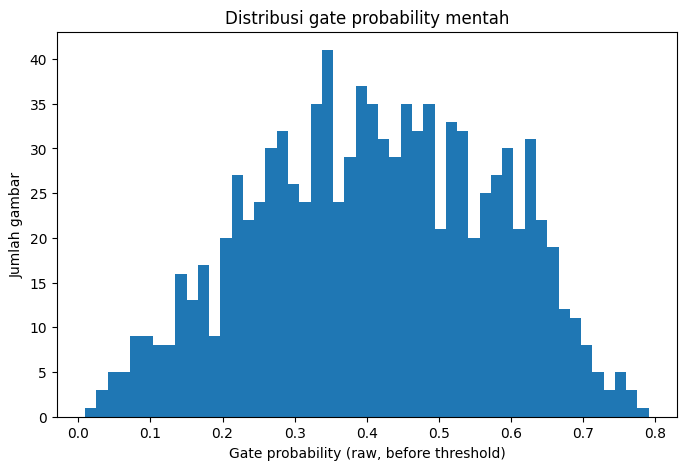

count    1000.000000
mean        0.410832
std         0.164265
min         0.009526
25%         0.285098
50%         0.412354
75%         0.535713
max         0.790766
Name: gate, dtype: float64


In [38]:
import torch
import numpy as np
import pandas as pd


def analyze_gate_ambiguity(full_model, router, detect_A, detect_B, criterion_A, criterion_B, val_loader, n_samples=None):
    device = next(full_model.parameters()).device
    results = []

    for i, batch in enumerate(val_loader):
        if n_samples is not None and i >= n_samples:
            break

        img = batch["img"].to(device).float() / 255.0
        model_list = list(full_model.model)
        pre_router_layers = model_list[0:16]
        x = img
        y = []
        for m in pre_router_layers:
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x)
        p3_neck = x
        p2_backbone = y[2]
        p4_neck = y[12]
        p5_sppf = y[9]
        gate_prob = compute_gate_probability_raw(router, p3_neck, p2_backbone)
        gate_value = float(gate_prob.flatten()[0])

        p2_out = router.compute_expert_only(p3_neck, p2_backbone)
        y_dict = {15: p3_neck, 12: p4_neck, 9: p5_sppf, 16: p2_out}
        xx = p2_out
        outputs_by_idx = {16: p2_out}
        branch_a_layers = model_list[17:26]
        for idx, m in zip(range(17, 26), branch_a_layers):
            if m.f != -1:
                if isinstance(m.f, int):
                    xx = outputs_by_idx.get(m.f, y_dict.get(m.f))
                else:
                    xx = [xx if j == -1 else outputs_by_idx.get(j, y_dict.get(j)) for j in m.f]
            xx = m(xx)
            outputs_by_idx[idx] = xx
        preds_A = detect_A([p2_out, outputs_by_idx[19], outputs_by_idx[22], outputs_by_idx[25]])

        xx = p3_neck
        outputs_by_idx_b = {}
        branch_b_layers = model_list[26:32]
        for idx, m in zip(range(26, 32), branch_b_layers):
            if m.f != -1:
                if isinstance(m.f, int):
                    xx = outputs_by_idx_b.get(m.f, y_dict.get(m.f))
                else:
                    xx = [xx if j == -1 else outputs_by_idx_b.get(j, y_dict.get(j)) for j in m.f]
            xx = m(xx)
            outputs_by_idx_b[idx] = xx
        preds_B = detect_B([p3_neck, outputs_by_idx_b[28], outputs_by_idx_b[31]])

        target = {
            "batch_idx": batch["batch_idx"].to(device),
            "cls": batch["cls"].to(device),
            "bboxes": batch["bboxes"].to(device),
        }
        with torch.no_grad():
            loss_A, _ = criterion_A(preds_A, target)
            loss_B, _ = criterion_B(preds_B, target)

        loss_A_val = float(loss_A.sum())
        loss_B_val = float(loss_B.sum())

        bboxes = batch["bboxes"]
        if bboxes.numel() > 0:
            areas = (bboxes[:, 2] * bboxes[:, 3]).cpu().numpy()
            mean_area = float(areas.mean())
            min_area = float(areas.min())
            n_objects = len(areas)
            n_small = int((areas < 0.01).sum())
        else:
            mean_area, min_area, n_objects, n_small = np.nan, np.nan, 0, 0

        results.append({
            "gate": gate_value, "loss_A": loss_A_val, "loss_B": loss_B_val,
            "loss_diff": loss_B_val - loss_A_val,
            "mean_obj_area": mean_area, "min_obj_area": min_area,
            "n_objects": n_objects, "n_small_objects": n_small,
            "is_ambiguous_gate": 0.4 <= gate_value <= 0.6,
        })

        if (i + 1) % 100 == 0:
            print(f"  [{i+1}] processed...")

    return pd.DataFrame(results)


df = analyze_gate_ambiguity(full_model, router, detect_A, detect_B, criterion_A, criterion_B, val_loader, n_samples=1000)
df.to_csv("gate_ambiguity_analysis.csv", index=False)

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(df["gate"], bins=50)
plt.xlabel("Gate probability (raw, before threshold)")
plt.ylabel("Jumlah gambar")
plt.title("Distribusi gate probability mentah")
plt.savefig("gate_prob_distribution.png", dpi=150)
plt.show()

print(df["gate"].describe())

In [42]:
df["is_ambiguous_gate"] = (df["gate"] >= 0.4) & (df["gate"] <= 0.6)

ambiguous = df[df["is_ambiguous_gate"]]
confident = df[~df["is_ambiguous_gate"]]

print("=== Gambar dengan gate AMBIGU (0.4-0.6) ===")
print(f"n = {len(ambiguous)}")
print(f"mean |loss_diff| = {ambiguous['loss_diff'].abs().mean():.4f}")
print(f"std  |loss_diff| = {ambiguous['loss_diff'].abs().std():.4f}")

print("\n=== Gambar dengan gate TEGAS (<0.4 atau >0.6) ===")
print(f"n = {len(confident)}")
print(f"mean |loss_diff| = {confident['loss_diff'].abs().mean():.4f}")
print(f"std  |loss_diff| = {confident['loss_diff'].abs().std():.4f}")

from scipy import stats
t_stat, p_val = stats.mannwhitneyu(
    ambiguous["loss_diff"].abs(), confident["loss_diff"].abs(), alternative="less"
)
print(f"\nMann-Whitney U test (ambigu < tegas dalam |loss_diff|): p={p_val:.6f}")

# Tambahan: korelasi langsung antara gate confidence (jarak dari 0.5) vs |loss_diff|
df["gate_confidence"] = (df["gate"] - 0.5).abs()  # 0 = paling ragu, 0.5 = paling yakin
corr, p = stats.spearmanr(df["gate_confidence"], df["loss_diff"].abs())
print(f"\nSpearman correlation (gate confidence vs |loss_diff|): r={corr:.4f}, p={p:.2e}")

=== Gambar dengan gate AMBIGU (0.4-0.6) ===
n = 377
mean |loss_diff| = 0.2047
std  |loss_diff| = 0.2280

=== Gambar dengan gate TEGAS (<0.4 atau >0.6) ===
n = 623
mean |loss_diff| = 0.2186
std  |loss_diff| = 0.2326

Mann-Whitney U test (ambigu < tegas dalam |loss_diff|): p=0.207177

Spearman correlation (gate confidence vs |loss_diff|): r=0.0573, p=6.99e-02


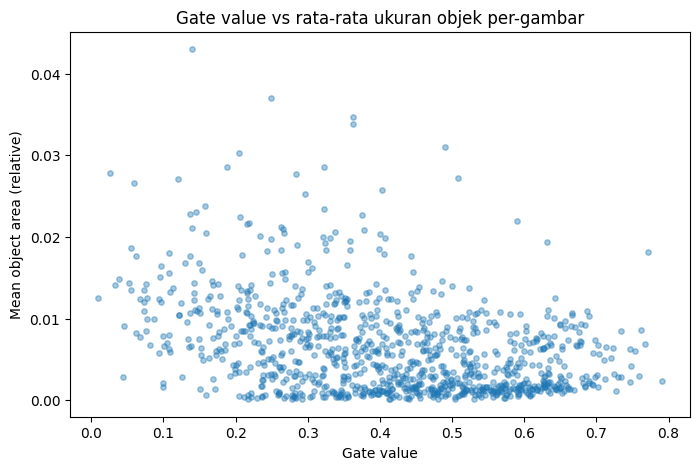

Spearman correlation (gate vs mean obj area): r=-0.3447, p=2.84e-29
Spearman correlation (gate vs jumlah objek kecil): r=-0.1906, p=1.23e-09


In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df["gate"], df["mean_obj_area"], alpha=0.4, s=15)
plt.xlabel("Gate value")
plt.ylabel("Mean object area (relative)")
plt.title("Gate value vs rata-rata ukuran objek per-gambar")
plt.savefig("gate_vs_objsize.png", dpi=150)
plt.show()

# Korelasi Spearman (non-parametrik, cocok untuk data non-linear)
corr, p = stats.spearmanr(df["gate"], df["mean_obj_area"])
print(f"Spearman correlation (gate vs mean obj area): r={corr:.4f}, p={p:.2e}")

corr2, p2 = stats.spearmanr(df["gate"], df["n_small_objects"])
print(f"Spearman correlation (gate vs jumlah objek kecil): r={corr2:.4f}, p={p2:.2e}")